# Analysing and Predicting Material Asset-Allocation Transitions among Retirement Benefits Schemes in Kenya

## End-to-end applied machine-learning capstone

### Project objective

This project analyses asset-allocation patterns and year-to-year portfolio transitions among retirement benefits schemes in Kenya, then develops a binary classifier to predict whether a scheme will experience a material asset-allocation change in the following reporting year.

A **material asset-allocation change** is an absolute change of at least **five percentage points (0.05)** in the share of any one of the nine asset classes between consecutive reporting years. The anonymised scheme-level RBA administrative data cover 2013–2025.

### Notebook workflow

1. Data loading, cleaning and validation.
2. Portfolio feature engineering and descriptive analysis.
3. Next-year binary target construction and chronological data partitions.
4. Baseline and supervised classification modelling.
5. Validation-based model selection and threshold assessment.
6. Held-out test evaluation, calibration and sensitivity analysis.
7. SHAP interpretation and model-artifact export.

> **Data confidentiality:** the raw RBA dataset is not embedded in this notebook. Anyone running it must have authorised access to a local copy. Do not upload raw administrative data to a public repository unless the data owner has explicitly permitted this.

## 1. Environment setup

In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

sns.set_theme(style="whitegrid")

print("Python data-analysis libraries imported successfully.")

Python data-analysis libraries imported successfully.


## 2. Data loading and initial inspection

### 2.1 Locate the authorised CSV file

The notebook does not depend on a personal Windows path. It searches the current VS Code/Jupyter working directory and its parent folders for the expected CSV. It checks the project root and the common `data/`, `data/raw/` and `notebooks/` locations.

The loader accepts the original filename `COPY 1 FINAL.csv` and downloaded variants such as `COPY 1 FINAL(2).csv`. If the file is stored elsewhere, set `RBA_DATA_PATH` to its full path on that computer.

**Recommended project layout for later:**

```text
Pension_Asset_Allocation_Capstone/
├── data/
│   └── raw/
│       └── COPY 1 FINAL.csv
└── notebooks/
    └── Pension_Asset_Allocation_Capstone.ipynb
```

For the current working stage, the CSV and notebook may also be kept together in the project folder.

In [2]:

# ============================================================
# DATA LOADING
# ============================================================

import pandas as pd
from pathlib import Path

# Exact location of the RBA dataset
DATA_PATH = Path(
    r"C:\Users\User\OneDrive\Documents\AML CAPSTONE PROJECT\COPY 1 FINAL.csv"
)

# Confirm that the dataset exists
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Cannot find the dataset at: {DATA_PATH}"
    )

# Load the original dataset
df_raw = pd.read_csv(DATA_PATH)

# Create a working copy
df = df_raw.copy()

print("Raw dataset loaded successfully!")
print("Dataset shape:", df_raw.shape)

display(df_raw.head())


Raw dataset loaded successfully!
Dataset shape: (16851, 25)


,Ref,Period,Month,Year,"Cash, Demand & Fixed Deposits",Cash and Demand Deposits,Commercial Paper and Corporate Bonds,Fixed and Time Deposits,Guaranteed Funds,Immovable Property,Kenya Government Securities,Offshore Investments,Property Unit Trusts,Quoted Equity,Unquoted Equity,"Cash, Demand & Fixed Deposits - Income",Commercial Paper and Corporate Bonds - Income,Fixed and Time Deposits - Income,Guaranteed Funds - Income,Immovable Property - Income,Kenya Government Securities - Income,Offshore Investments - Income,Property Unit Trusts - Income,Quoted Equity - Income,Unquoted Equity - Income
0,1.0000,14-Jun,6.0000,"2,014.0000",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1,1.0000,14-Dec,12.0000,"2,014.0000",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2,1.0000,15-Dec,12.0000,"2,015.0000",0.0000,0.0000,0.0000,0.0000,"16,857,240.0000",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,"1,219,378.0000",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
3,1.0000,16-Dec,12.0000,"2,016.0000",0.0000,0.0000,0.0000,0.0000,"21,291,790.0000",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,"1,644,931.0000",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
4,1.0000,17-Dec,12.0000,"2,017.0000",0.0000,0.0000,0.0000,0.0000,"26,433,672.0000",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,"2,238,169.0000",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


In [3]:
# Confirm that the uploaded file contains the columns expected by this analysis.
required_source_columns = [
    "Ref", "Period", "Month", "Year",
    "Cash, Demand & Fixed Deposits",
    "Cash and Demand Deposits",
    "Commercial Paper and Corporate Bonds",
    "Fixed and Time Deposits",
    "Guaranteed Funds",
    "Immovable Property",
    "Kenya Government Securities",
    "Offshore Investments",
    "Property Unit Trusts",
    "Quoted Equity",
    "Unquoted Equity",
    "Cash, Demand & Fixed Deposits - Income",
    "Commercial Paper and Corporate Bonds - Income",
    "Fixed and Time Deposits - Income",
    "Guaranteed Funds - Income",
    "Immovable Property - Income",
    "Kenya Government Securities - Income",
    "Offshore Investments - Income",
    "Property Unit Trusts - Income",
    "Quoted Equity - Income",
    "Unquoted Equity - Income"
]

missing_source_columns = [
    column for column in required_source_columns
    if column not in df_raw.columns
]

if missing_source_columns:
    raise ValueError(
        "The source CSV is missing columns required by this notebook: "
        f"{missing_source_columns}"
    )

print("All expected source columns are present.")
print("Raw rows and columns:", df_raw.shape)

display(df_raw.head())
display(df_raw.dtypes.rename("Data type").to_frame())

All expected source columns are present.
Raw rows and columns: (16851, 25)


,Ref,Period,Month,Year,"Cash, Demand & Fixed Deposits",Cash and Demand Deposits,Commercial Paper and Corporate Bonds,Fixed and Time Deposits,Guaranteed Funds,Immovable Property,Kenya Government Securities,Offshore Investments,Property Unit Trusts,Quoted Equity,Unquoted Equity,"Cash, Demand & Fixed Deposits - Income",Commercial Paper and Corporate Bonds - Income,Fixed and Time Deposits - Income,Guaranteed Funds - Income,Immovable Property - Income,Kenya Government Securities - Income,Offshore Investments - Income,Property Unit Trusts - Income,Quoted Equity - Income,Unquoted Equity - Income
0,1.0000,14-Jun,6.0000,"2,014.0000",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1,1.0000,14-Dec,12.0000,"2,014.0000",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2,1.0000,15-Dec,12.0000,"2,015.0000",0.0000,0.0000,0.0000,0.0000,"16,857,240.0000",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,"1,219,378.0000",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
3,1.0000,16-Dec,12.0000,"2,016.0000",0.0000,0.0000,0.0000,0.0000,"21,291,790.0000",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,"1,644,931.0000",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
4,1.0000,17-Dec,12.0000,"2,017.0000",0.0000,0.0000,0.0000,0.0000,"26,433,672.0000",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,"2,238,169.0000",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


,Data type
Ref,float64
Period,object
Month,float64
Year,float64
"Cash, Demand & Fixed Deposits",float64
Cash and Demand Deposits,float64
Commercial Paper and Corporate Bonds,float64
Fixed and Time Deposits,float64
Guaranteed Funds,float64
Immovable Property,float64


In [4]:
reporting_columns = ["Period", "Month", "Year"]

raw_data_quality_summary = pd.Series({
    "Raw observations": len(df_raw),
    "Raw columns": df_raw.shape[1],
    "Completely empty rows": int(df_raw.isna().all(axis=1).sum()),
    "Rows missing Month or Year": int(df_raw[["Month", "Year"]].isna().any(axis=1).sum()),
    "Rows missing all reporting fields": int(df_raw[reporting_columns].isna().all(axis=1).sum()),
    "Distinct non-missing scheme references": int(df_raw["Ref"].nunique())
}, name="Value").to_frame()

display(raw_data_quality_summary)

,Value
Raw observations,16851
Raw columns,25
Completely empty rows,1153
Rows missing Month or Year,1742
Rows missing all reporting fields,1742
Distinct non-missing scheme references,1153


## 3. Initial cleaning and annual scheme-year construction

### 3.1 Remove completely empty records

Completely empty rows contain no scheme, reporting-period or financial information. They are removed from the working copy only; `df_raw` remains unchanged.

In [5]:
rows_before = len(df)
df = df.dropna(how="all").copy().reset_index(drop=True)

print("Completely empty rows removed:", rows_before - len(df))
print("Shape after removing completely empty rows:", df.shape)

Completely empty rows removed: 1153
Shape after removing completely empty rows: (15698, 25)


### 3.2 Set aside records without a usable reporting month or year

The annual panel requires both `Month` and `Year`. Records missing either field are preserved separately for audit and excluded from the dated working dataset. The original source records remain available in `df_raw`.

In [6]:
missing_date_mask = df[["Month", "Year"]].isna().any(axis=1)
df_without_reporting_month_year = df.loc[missing_date_mask].copy()

df = df.loc[~missing_date_mask].copy().reset_index(drop=True)

print("Records set aside because Month or Year is missing:", len(df_without_reporting_month_year))
print("Shape after removing undated records:", df.shape)

Records set aside because Month or Year is missing: 589
Shape after removing undated records: (15109, 25)


### 3.3 Validate and convert reporting fields

`Ref`, `Month` and `Year` are converted to numeric values and checked before integer conversion. Invalid months, non-integer identifiers or missing scheme references stop the workflow rather than being silently coerced.

In [7]:
for column in ["Ref", "Month", "Year"]:
    df[column] = pd.to_numeric(df[column], errors="raise")

for column in ["Ref", "Month", "Year"]:
    if df[column].isna().any():
        raise ValueError(f"{column} contains missing values among dated records.")
    if not np.equal(df[column], np.floor(df[column])).all():
        raise ValueError(f"{column} contains non-integer values.")

if not df["Month"].between(1, 12).all():
    invalid_months = sorted(df.loc[~df["Month"].between(1, 12), "Month"].unique())
    raise ValueError(f"Month contains values outside 1–12: {invalid_months}")

# Convert only after all checks have passed.
df = df.astype({"Ref": "int64", "Month": "int64", "Year": "int64"})

print("Reporting fields validated and converted.")
print("Reporting year range:", int(df["Year"].min()), "to", int(df["Year"].max()))
print("Reporting month range:", int(df["Month"].min()), "to", int(df["Month"].max()))

Reporting fields validated and converted.
Reporting year range: 2013 to 2025
Reporting month range: 1 to 12


### 3.4 Construct a reporting-period date

A date is constructed from the reported year and month, using the first day of the reporting month. This supports consistent chronological ordering.

In [8]:
df["Reporting_Period"] = pd.to_datetime(
    {"year": df["Year"], "month": df["Month"], "day": 1},
    errors="raise"
)

months_correct = (df["Reporting_Period"].dt.month == df["Month"]).all()
years_correct = (df["Reporting_Period"].dt.year == df["Year"]).all()

print("Constructed months agree with source:", months_correct)
print("Constructed years agree with source:", years_correct)
assert months_correct and years_correct

display(df[["Ref", "Period", "Month", "Year", "Reporting_Period"]].head(10))

Constructed months agree with source: True
Constructed years agree with source: True


,Ref,Period,Month,Year,Reporting_Period
0,1,14-Jun,6,2014,2014-06-01
1,1,14-Dec,12,2014,2014-12-01
2,1,15-Dec,12,2015,2015-12-01
3,1,16-Dec,12,2016,2016-12-01
4,1,17-Dec,12,2017,2017-12-01
5,1,21-Dec,12,2021,2021-12-01
6,1,22-Jun,6,2022,2022-06-01
7,4,13-Dec,12,2013,2013-12-01
8,4,15-Dec,12,2015,2015-12-01
9,4,16-Dec,12,2016,2016-12-01


### 3.5 Sort records and identify multiple reports within scheme-years

Some schemes submitted more than one report in a calendar year. Records are sorted by scheme, year and month. The latest available reporting month is retained for the annual panel; earlier reports are stored separately.

The source file has no separate submission timestamp. If two reports had the same latest month for a scheme-year, the selection would need manual review. The check below verifies that this ambiguity does not occur in the supplied dataset.

In [9]:
df = df.sort_values(
    by=["Ref", "Year", "Month"],
    ascending=[True, True, True],
    kind="stable"
).reset_index(drop=True)

# Check whether any scheme-year has more than one record in its latest month.
max_month_by_scheme_year = df.groupby(["Ref", "Year"])["Month"].transform("max")
latest_month_rows = df.loc[df["Month"].eq(max_month_by_scheme_year)]
latest_month_counts = latest_month_rows.groupby(["Ref", "Year"]).size()
latest_month_ties = latest_month_counts.loc[latest_month_counts > 1]

print("Scheme-year groups tied at the latest reporting month:", len(latest_month_ties))
if not latest_month_ties.empty:
    display(latest_month_ties.to_frame("Records at latest month"))
    raise ValueError(
        "Some scheme-years have multiple reports in the same latest month. "
        "Review these records before selecting an annual report."
    )

multiple_rows = df.loc[
    df.duplicated(subset=["Ref", "Year"], keep=False)
].copy()

print("Records belonging to scheme-years with multiple reports:", len(multiple_rows))
display(multiple_rows[["Ref", "Year", "Month", "Reporting_Period"]].head(30))

Scheme-year groups tied at the latest reporting month: 0
Records belonging to scheme-years with multiple reports: 4064


,Ref,Year,Month,Reporting_Period
0,1,2014,6,2014-06-01
1,1,2014,12,2014-12-01
26,11,2013,1,2013-01-01
27,11,2013,12,2013-12-01
28,11,2014,1,2014-01-01
29,11,2014,12,2014-12-01
30,11,2015,1,2015-01-01
31,11,2015,3,2015-03-01
32,11,2016,3,2016-03-01
33,11,2016,6,2016-06-01


In [10]:
# Preserve all valid dated reports.
df_all_reports = df.copy()

# Mark earlier reports within each Ref-Year group.
earlier_report_mask = df_all_reports.duplicated(
    subset=["Ref", "Year"],
    keep="last"
)

df_earlier_reports = df_all_reports.loc[earlier_report_mask].copy()
df_annual = df_all_reports.loc[~earlier_report_mask].copy().reset_index(drop=True)

print("All valid dated reports:", df_all_reports.shape)
print("Earlier reports stored separately:", df_earlier_reports.shape)
print("Annual scheme-year dataset:", df_annual.shape)
print("Duplicate Ref-Year combinations in annual dataset:", df_annual.duplicated(["Ref", "Year"]).sum())
print("Unique schemes in annual dataset:", df_annual["Ref"].nunique())

assert df_annual.duplicated(["Ref", "Year"]).sum() == 0

All valid dated reports: (15109, 26)
Earlier reports stored separately: (2082, 26)
Annual scheme-year dataset: (13027, 26)
Duplicate Ref-Year combinations in annual dataset: 0
Unique schemes in annual dataset: 1153


### Checkpoint 1: initial cleaning complete

At this stage, the notebook has preserved the raw source data, removed empty and undated records from the working data, validated the reporting fields, constructed `Reporting_Period`, and created a one-record-per-scheme-year annual dataset. The earlier reports remain available in `df_earlier_reports` for traceability.

The next section examines financial-data quality before any asset-allocation shares are calculated.

## 4. Data-quality checks and construction of the modelling preparation dataset

### 4.1 Confirm annual uniqueness

There should be no more than one retained observation for each scheme reference and reporting year.

In [11]:
duplicate_scheme_years = df_annual.loc[
    df_annual.duplicated(subset=["Ref", "Year"], keep=False)
].sort_values(["Ref", "Year", "Month"])

print("Remaining duplicate scheme-year rows:", len(duplicate_scheme_years))
assert duplicate_scheme_years.empty

Remaining duplicate scheme-year rows: 0


### 4.2 Reconcile the cash investment fields

The source contains a combined `Cash, Demand & Fixed Deposits` value and two component fields. The component sum is compared with the combined value. The combined source field is retained for analysis; mismatches are flagged rather than silently overwritten.

In [12]:
cash_combined_column = "Cash, Demand & Fixed Deposits"
cash_component_columns = ["Cash and Demand Deposits", "Fixed and Time Deposits"]

cash_components_total = df_annual[cash_component_columns].sum(axis=1, min_count=2)
cash_difference = df_annual[cash_combined_column] - cash_components_total
cash_mismatch_mask = cash_difference.abs() > 1.0

cash_reconciliation = df_annual.loc[
    cash_mismatch_mask,
    ["Ref", "Year", "Month", cash_combined_column] + cash_component_columns
].copy()
cash_reconciliation["Cash_Difference"] = cash_difference.loc[cash_mismatch_mask]

print("Cash reconciliation mismatches (absolute difference > 1):", len(cash_reconciliation))
display(cash_reconciliation)

Cash reconciliation mismatches (absolute difference > 1): 1


,Ref,Year,Month,"Cash, Demand & Fixed Deposits",Cash and Demand Deposits,Fixed and Time Deposits,Cash_Difference
17,10,2018,12,"16,754,050.0000",0.0000,0.0000,"16,754,050.0000"


**Interpretation:** the supplied data contain one cash reconciliation mismatch. The combined cash/deposit value is retained as reported in the source, and the component columns remain available in `df_annual` for audit. This notebook does not invent a corrected value.

### 4.3 Define the nine asset classes and their corresponding income fields

The project uses the combined cash/deposits field and the other eight asset classes. The standalone `Fixed and Time Deposits - Income` field is checked separately because it is not included in the nine-class mapping used in the original analysis.

In [13]:
asset_income_pairs = {
    "Cash, Demand & Fixed Deposits": "Cash, Demand & Fixed Deposits - Income",
    "Commercial Paper and Corporate Bonds": "Commercial Paper and Corporate Bonds - Income",
    "Guaranteed Funds": "Guaranteed Funds - Income",
    "Immovable Property": "Immovable Property - Income",
    "Kenya Government Securities": "Kenya Government Securities - Income",
    "Offshore Investments": "Offshore Investments - Income",
    "Property Unit Trusts": "Property Unit Trusts - Income",
    "Quoted Equity": "Quoted Equity - Income",
    "Unquoted Equity": "Unquoted Equity - Income"
}

asset_columns = list(asset_income_pairs.keys())
income_columns = list(asset_income_pairs.values())
financial_columns = asset_columns + income_columns

fixed_deposit_income_column = "Fixed and Time Deposits - Income"
fixed_deposit_income_summary = df_annual[fixed_deposit_income_column].value_counts(dropna=False)
fixed_deposit_income_nonzero = int(df_annual[fixed_deposit_income_column].fillna(0).ne(0).sum())

print("Standalone Fixed and Time Deposits - Income value counts:")
display(fixed_deposit_income_summary.to_frame("Records"))
print("Non-zero standalone fixed-deposit income records:", fixed_deposit_income_nonzero)

if fixed_deposit_income_nonzero > 0:
    raise ValueError(
        "Fixed and Time Deposits - Income contains non-zero values. "
        "Review the income mapping before proceeding."
    )

Standalone Fixed and Time Deposits - Income value counts:


,Records
Fixed and Time Deposits - Income,
0.0000,13027


Non-zero standalone fixed-deposit income records: 0


### 4.4 Create the analysis copy and assess missing financial values

`df_annual` remains unchanged. The two cash component investment fields are removed from the analysis copy because the combined cash/deposit class is used. The standalone fixed/time-deposit income field is also omitted because it is zero throughout the supplied annual dataset.

Missing financial values are treated explicitly. Rows with all mapped investment and income fields missing are stored separately. Rows with only some financial fields missing are also stored separately rather than having missing values silently treated as zero.

In [14]:
df_clean = df_annual.drop(
    columns=cash_component_columns + [fixed_deposit_income_column]
).copy()

missing_by_financial_column = pd.DataFrame({
    "Missing_Count": df_clean[financial_columns].isna().sum(),
    "Missing_Percentage": df_clean[financial_columns].isna().mean().mul(100)
}).sort_values("Missing_Count", ascending=False)

display(missing_by_financial_column)

all_financial_missing_mask = df_clean[financial_columns].isna().all(axis=1)
partial_financial_missing_mask = (
    df_clean[financial_columns].isna().any(axis=1)
    & ~all_financial_missing_mask
)

df_missing_financial = df_clean.loc[all_financial_missing_mask].copy()
df_partial_financial = df_clean.loc[partial_financial_missing_mask].copy()

df_clean = df_clean.loc[
    ~(all_financial_missing_mask | partial_financial_missing_mask)
].copy().reset_index(drop=True)

print("Rows with all mapped financial fields missing:", len(df_missing_financial))
print("Rows with partially missing mapped financial fields:", len(df_partial_financial))
print("Rows retained for financial quality assessment:", len(df_clean))

if not df_partial_financial.empty:
    print("Partially missing records have been preserved separately and excluded from portfolio calculations.")

,Missing_Count,Missing_Percentage
"Cash, Demand & Fixed Deposits",52,0.3992
Commercial Paper and Corporate Bonds,52,0.3992
Guaranteed Funds,52,0.3992
Immovable Property,52,0.3992
Kenya Government Securities,52,0.3992
Offshore Investments,52,0.3992
Property Unit Trusts,52,0.3992
Quoted Equity,52,0.3992
Unquoted Equity,52,0.3992
"Cash, Demand & Fixed Deposits - Income",52,0.3992


Rows with all mapped financial fields missing: 52
Rows with partially missing mapped financial fields: 0
Rows retained for financial quality assessment: 12975


### 4.5 Calculate complete portfolio totals

Investment and income totals are calculated only when all nine corresponding values are present. The use of `min_count` prevents pandas from treating missing values as zero.

In [15]:
df_clean["Total_Investments"] = df_clean[asset_columns].sum(
    axis=1,
    min_count=len(asset_columns)
)
df_clean["Total_Income"] = df_clean[income_columns].sum(
    axis=1,
    min_count=len(income_columns)
)

assert df_clean["Total_Investments"].notna().all()
assert df_clean["Total_Income"].notna().all()

print("Total investment values successfully calculated.")
display(df_clean[["Ref", "Year", "Total_Investments", "Total_Income"]].head())

Total investment values successfully calculated.


,Ref,Year,Total_Investments,Total_Income
0,1,2014,0.0000,0.0000
1,1,2015,"16,857,240.0000","1,219,378.0000"
2,1,2016,"21,291,790.0000","1,644,931.0000"
3,1,2017,"26,433,672.0000","2,238,169.0000"
4,1,2021,0.0000,0.0000


### 4.6 Review income values relative to investment balances

Income is a flow recorded over a reporting period, whereas investment values are portfolio balances reported at a point in time. Therefore, income exceeding the corresponding investment balance is a review flag, not automatically a data error.

In [16]:
income_quality_checks = []
unusual_income_cases = []

for asset_column, income_column in asset_income_pairs.items():
    available = df_clean[asset_column].notna() & df_clean[income_column].notna()
    positive_investment = available & df_clean[asset_column].gt(0)
    income_exceeds = positive_investment & df_clean[income_column].gt(df_clean[asset_column])

    income_quality_checks.append({
        "Asset_Class": asset_column,
        "Income_Greater_Than_Investment": int(income_exceeds.sum()),
        "Positive_Income_Zero_Investment": int((available & df_clean[income_column].gt(0) & df_clean[asset_column].eq(0)).sum()),
        "Negative_Income": int((available & df_clean[income_column].lt(0)).sum()),
        "Negative_Investment": int((available & df_clean[asset_column].lt(0)).sum())
    })

    if income_exceeds.any():
        temporary = df_clean.loc[
            income_exceeds,
            ["Ref", "Year", "Reporting_Period", asset_column, income_column]
        ].copy()
        temporary = temporary.rename(columns={
            asset_column: "Investment_Amount",
            income_column: "Income_Amount"
        })
        temporary["Asset_Class"] = asset_column
        temporary["Income_to_Investment_Ratio"] = (
            temporary["Income_Amount"] / temporary["Investment_Amount"]
        )
        unusual_income_cases.append(temporary)

income_check_summary = pd.DataFrame(income_quality_checks)
display(income_check_summary)

if unusual_income_cases:
    unusual_positive_cases = pd.concat(unusual_income_cases, ignore_index=True)
    unusual_positive_cases = unusual_positive_cases.sort_values(
        "Income_to_Investment_Ratio", ascending=False
    ).reset_index(drop=True)
else:
    unusual_positive_cases = pd.DataFrame(columns=[
        "Ref", "Year", "Reporting_Period", "Investment_Amount",
        "Income_Amount", "Asset_Class", "Income_to_Investment_Ratio"
    ])

print("Asset-class cases where income exceeds a positive investment balance:", len(unusual_positive_cases))
display(unusual_positive_cases.head(20))

,Asset_Class,Income_Greater_Than_Investment,Positive_Income_Zero_Investment,Negative_Income,Negative_Investment
0,"Cash, Demand & Fixed Deposits",57,283,1,0
1,Commercial Paper and Corporate Bonds,34,342,2,0
2,Guaranteed Funds,35,122,0,1
3,Immovable Property,4,30,3,0
4,Kenya Government Securities,10,110,0,0
5,Offshore Investments,3,33,7,0
6,Property Unit Trusts,5,52,1,0
7,Quoted Equity,19,112,1,0
8,Unquoted Equity,3,53,0,0


Asset-class cases where income exceeds a positive investment balance: 170


,Ref,Year,Reporting_Period,Investment_Amount,Income_Amount,Asset_Class,Income_to_Investment_Ratio
0,1139,2019,2019-12-01,540.0000,"1,873,000.0000",Quoted Equity,"3,468.5185"
1,799,2018,2018-12-01,"4,420.0000","12,883,214.0000",Guaranteed Funds,"2,914.7543"
2,745,2023,2023-06-01,"19,058.0000","36,742,994.0000",Kenya Government Securities,"1,927.9564"
3,799,2019,2019-12-01,"27,991.0000","16,958,308.0000",Guaranteed Funds,605.8486
4,474,2023,2023-12-01,"281,969.0000","56,878,848.0000",Commercial Paper and Corporate Bonds,201.7202
5,1083,2020,2020-12-01,"1,423,000.0000","222,483,000.0000",Immovable Property,156.3479
6,742,2022,2022-12-01,"6,664.0000","915,939.0000","Cash, Demand & Fixed Deposits",137.4458
7,723,2016,2016-12-01,"272,954.0000","19,851,417.0000","Cash, Demand & Fixed Deposits",72.7281
8,135,2023,2023-12-01,"15,043,367.0000","858,915,497.0000",Kenya Government Securities,57.0960
9,1655,2018,2018-12-01,"2,197,000.0000","118,258,000.0000",Immovable Property,53.8270


### 4.7 Review portfolio income ratios and extreme yields

As in the original exploratory notebook, the overall income-to-investment ratio and an average-balance yield are calculated for review. The average-balance yield uses the current and immediately preceding year's total investments. Observations with an absolute yield above 100% are flagged for inspection only; they are **not automatically removed** from the modelling preparation data.

In [17]:
review_data = df_clean.sort_values(["Ref", "Year"]).copy().reset_index(drop=True)

review_data["Portfolio_Income_Ratio"] = (
    review_data["Total_Income"] / review_data["Total_Investments"]
).where(review_data["Total_Investments"] > 0)

review_data["Previous_Observed_Year"] = (
    review_data.groupby("Ref")["Year"].shift(1)
)
review_data["Previous_Total_Investments"] = (
    review_data.groupby("Ref")["Total_Investments"].shift(1)
)

review_data["Previous_Year_Consecutive"] = (
    review_data["Year"] - review_data["Previous_Observed_Year"]
).eq(1)

review_data.loc[
    ~review_data["Previous_Year_Consecutive"],
    "Previous_Total_Investments"
] = np.nan

review_data["Average_Total_Investments"] = (
    review_data["Previous_Total_Investments"] + review_data["Total_Investments"]
) / 2

review_data["Average_Income_Yield"] = (
    review_data["Total_Income"] / review_data["Average_Total_Investments"]
).where(review_data["Average_Total_Investments"] > 0)

review_data["Extreme_Portfolio_Yield"] = (
    review_data["Average_Income_Yield"].abs() > 1
)

df_extreme_portfolio = review_data.loc[review_data["Extreme_Portfolio_Yield"]].copy()

print("Observations with an absolute average-balance income yield above 100%:", len(df_extreme_portfolio))
print("These observations are flagged for review and are not automatically excluded.")
display(
    df_extreme_portfolio[
        ["Ref", "Year", "Total_Investments", "Total_Income",
         "Average_Total_Investments", "Average_Income_Yield"]
    ].head(20)
)

df_non_extreme = review_data.loc[~review_data["Extreme_Portfolio_Yield"]].copy()
print("Other observations (not flagged by the 100% review threshold):", len(df_non_extreme))

Observations with an absolute average-balance income yield above 100%: 42
These observations are flagged for review and are not automatically excluded.


,Ref,Year,Total_Investments,Total_Income,Average_Total_Investments,Average_Income_Yield
925,164,2021,"200,746,213.0000","188,823,510.0000","186,671,236.0000",1.0115
926,164,2022,"191,873,948.0000","217,800,109.0000","196,310,080.5000",1.1095
1622,310,2022,"775,529,573.0000","803,358,282.0000","766,530,844.5000",1.0480
1623,310,2023,"856,593,755.0000","856,184,280.0000","816,061,664.0000",1.0492
1624,310,2024,"904,289,533.0000","956,815,115.0000","880,441,644.0000",1.0867
1625,310,2025,"1,038,431,393.0000","1,009,595,235.0000","971,360,463.0000",1.0394
1636,311,2023,"33,307,241.0000","32,965,282.0000","16,653,620.5000",1.9795
1637,311,2024,"40,098,930.0000","37,728,112.0000","36,703,085.5000",1.0279
1638,311,2025,"34,104,131.0000","44,228,108.0000","37,101,530.5000",1.1921
1752,337,2021,"3,801,550.0000","5,811,248.0000","1,900,775.0000",3.0573


Other observations (not flagged by the 100% review threshold): 12933


### 4.8 Summarise zero and negative financial values

Zero investment values are not the same as missing values. Negative investment balances are isolated because they prevent ordinary allocation-share interpretation. Negative income is reviewed separately because it can reflect losses, expenses, reversals or other accounting outcomes.

In [18]:
zero_investment_mask = df_clean[asset_columns].eq(0).all(axis=1)
zero_income_mask = df_clean[income_columns].eq(0).all(axis=1)
negative_investment_mask = (df_clean[asset_columns] < 0).any(axis=1)
negative_income_mask_clean = (df_clean[income_columns] < 0).any(axis=1)

portfolio_quality_summary = pd.DataFrame({
    "Condition": [
        "All investment classes are zero",
        "All income classes are zero",
        "Zero investments and zero income",
        "Zero investments but positive income",
        "At least one negative investment value",
        "At least one negative income value"
    ],
    "Number_of_Observations": [
        int(zero_investment_mask.sum()),
        int(zero_income_mask.sum()),
        int((df_clean["Total_Investments"].eq(0) & df_clean["Total_Income"].eq(0)).sum()),
        int((df_clean["Total_Investments"].eq(0) & df_clean["Total_Income"].gt(0)).sum()),
        int(negative_investment_mask.sum()),
        int(negative_income_mask_clean.sum())
    ]
})

display(portfolio_quality_summary)

,Condition,Number_of_Observations
0,All investment classes are zero,1772
1,All income classes are zero,1890
2,Zero investments and zero income,1681
3,Zero investments but positive income,91
4,At least one negative investment value,1
5,At least one negative income value,14


In [19]:
# Preserve negative-investment observations separately.
df_negative_investment = df_clean.loc[negative_investment_mask].copy()
df_negative_investment["Review_Reason"] = (
    "Negative investment balance; inspect the source record before allocation analysis."
)

negative_investment_entries = []
for asset_column in asset_columns:
    affected = df_clean.loc[
        df_clean[asset_column] < 0,
        ["Ref", "Year", "Reporting_Period", asset_column]
    ].copy()
    if not affected.empty:
        affected = affected.rename(columns={asset_column: "Negative_Investment"})
        affected["Asset_Class"] = asset_column
        negative_investment_entries.append(
            affected[["Ref", "Year", "Reporting_Period", "Asset_Class", "Negative_Investment"]]
        )

if negative_investment_entries:
    negative_investment_detail_table = pd.concat(negative_investment_entries, ignore_index=True)
else:
    negative_investment_detail_table = pd.DataFrame(columns=[
        "Ref", "Year", "Reporting_Period", "Asset_Class", "Negative_Investment"
    ])

print("Scheme-year observations with negative investment balances:", len(df_negative_investment))
display(negative_investment_detail_table)

Scheme-year observations with negative investment balances: 1


,Ref,Year,Reporting_Period,Asset_Class,Negative_Investment
0,466,2019,2019-12-01,Guaranteed Funds,"-201,926,073.0000"


### 4.9 Retain negative income observations for review

Negative income is documented but not automatically excluded. The affected scheme-years and the affected asset-class income entries are retained in separate review tables.

In [20]:
# Exclude only observations with negative investment balances at this stage.
df_after_negative_investment = df_clean.loc[~negative_investment_mask].copy().reset_index(drop=True)

negative_income_mask = (df_after_negative_investment[income_columns] < 0).any(axis=1)
df_negative_income = df_after_negative_investment.loc[negative_income_mask].copy()

negative_income_details = []
for income_column in income_columns:
    affected = df_after_negative_investment.loc[
        df_after_negative_investment[income_column] < 0,
        ["Ref", "Year", "Reporting_Period", income_column]
    ].copy()
    if not affected.empty:
        affected["Income_Class"] = income_column
        affected = affected.rename(columns={income_column: "Negative_Income"})
        negative_income_details.append(
            affected[["Ref", "Year", "Reporting_Period", "Income_Class", "Negative_Income"]]
        )

if negative_income_details:
    negative_income_detail_table = pd.concat(negative_income_details, ignore_index=True)
    negative_income_detail_table = negative_income_detail_table.sort_values(
        "Negative_Income"
    ).reset_index(drop=True)
else:
    negative_income_detail_table = pd.DataFrame(columns=[
        "Ref", "Year", "Reporting_Period", "Income_Class", "Negative_Income"
    ])

print("Scheme-year observations with negative income retained:", len(df_negative_income))
print("Negative income entries:", len(negative_income_detail_table))
display(negative_income_detail_table)

# Add matching investment and portfolio context for each negative-income entry.
negative_income_context_parts = []
for asset_column, income_column in asset_income_pairs.items():
    affected = df_after_negative_investment.loc[
        df_after_negative_investment[income_column] < 0,
        ["Ref", "Year", "Reporting_Period", asset_column, income_column,
         "Total_Investments", "Total_Income"]
    ].copy()
    if not affected.empty:
        affected = affected.rename(columns={
            asset_column: "Matching_Investment",
            income_column: "Negative_Income"
        })
        affected["Asset_Class"] = asset_column
        affected["Asset_Loss_Ratio"] = (
            affected["Negative_Income"] / affected["Matching_Investment"]
        ).where(affected["Matching_Investment"] > 0)
        affected["Portfolio_Income_Ratio"] = (
            affected["Total_Income"] / affected["Total_Investments"]
        ).where(affected["Total_Investments"] > 0)
        negative_income_context_parts.append(affected)

if negative_income_context_parts:
    negative_income_context = pd.concat(negative_income_context_parts, ignore_index=True)
    negative_income_context = negative_income_context.sort_values("Negative_Income")
else:
    negative_income_context = pd.DataFrame(columns=[
        "Ref", "Year", "Asset_Class", "Matching_Investment", "Negative_Income",
        "Asset_Loss_Ratio", "Total_Investments", "Total_Income", "Portfolio_Income_Ratio"
    ])

print("Negative-income context records:", len(negative_income_context))
display(negative_income_context[[
    "Ref", "Year", "Asset_Class", "Matching_Investment", "Negative_Income",
    "Asset_Loss_Ratio", "Total_Investments", "Total_Income", "Portfolio_Income_Ratio"
]])

Scheme-year observations with negative income retained: 14
Negative income entries: 15


,Ref,Year,Reporting_Period,Income_Class,Negative_Income
0,1843,2022,2022-12-01,Immovable Property - Income,"-517,947,305.0000"
1,30,2019,2019-06-01,Immovable Property - Income,"-151,819,295.1000"
2,1790,2013,2013-12-01,Property Unit Trusts - Income,"-38,000,000.0000"
3,373,2013,2013-12-01,Offshore Investments - Income,"-6,448,169.0000"
4,864,2013,2013-12-01,Offshore Investments - Income,"-2,757,000.0000"
5,346,2013,2013-12-01,Quoted Equity - Income,"-1,879,679.0000"
6,474,2013,2013-12-01,"Cash, Demand & Fixed Deposits - Income","-812,686.0000"
7,1631,2013,2013-12-01,Offshore Investments - Income,"-591,000.0000"
8,200,2022,2022-12-01,Immovable Property - Income,"-353,272.0000"
9,1048,2016,2016-12-01,Commercial Paper and Corporate Bonds - Income,"-341,442.0000"


Negative-income context records: 15


,Ref,Year,Asset_Class,Matching_Investment,Negative_Income,Asset_Loss_Ratio,Total_Investments,Total_Income,Portfolio_Income_Ratio
5,1843,2022,Immovable Property,"1,620,953,207.0000","-517,947,305.0000",-0.3195,"15,951,343,330.0000","974,850,468.0000",0.0611
3,30,2019,Immovable Property,"15,280,950,220.0000","-151,819,295.1000",-0.0099,"24,966,779,082.0000","597,818,865.9000",0.0239
13,1790,2013,Property Unit Trusts,0.0000,"-38,000,000.0000",NaN,"4,800,387,071.0000","375,283,600.0000",0.0782
8,373,2013,Offshore Investments,"4,680,284.0000","-6,448,169.0000",-1.3777,"693,299,303.0000","61,279,128.0000",0.0884
10,864,2013,Offshore Investments,"53,870,000.0000","-2,757,000.0000",-0.0512,"1,723,610,000.0000","135,219,000.0000",0.0785
14,346,2013,Quoted Equity,"53,098,627.0000","-1,879,679.0000",-0.0354,"165,127,582.0000","10,305,242.0000",0.0624
0,474,2013,"Cash, Demand & Fixed Deposits","17,630,484.0000","-812,686.0000",-0.0461,"202,745,221.0000","17,857,754.0000",0.0881
12,1631,2013,Offshore Investments,"141,580,000.0000","-591,000.0000",-0.0042,"1,806,600,000.0000","125,736,000.0000",0.0696
4,200,2022,Immovable Property,"7,150,495,492.0000","-353,272.0000",-0.0000,"16,168,735,279.0000","1,050,043,160.0000",0.0649
2,1048,2016,Commercial Paper and Corporate Bonds,0.0000,"-341,442.0000",NaN,"55,288,218.0000","5,533,172.0000",0.1001


### 4.10 Set aside non-positive investment portfolios

A scheme-year with zero or negative total investment cannot produce meaningful allocation shares. Such records are preserved in `df_nonpositive_portfolio` and excluded from `df_modelling`. The positive-investment modelling preparation data retain negative income observations.

In [21]:
df_after_negative_investment["Total_Investments"] = df_after_negative_investment[asset_columns].sum(
    axis=1, min_count=len(asset_columns)
)
df_after_negative_investment["Total_Income"] = df_after_negative_investment[income_columns].sum(
    axis=1, min_count=len(income_columns)
)

nonpositive_portfolio_mask = df_after_negative_investment["Total_Investments"] <= 0

df_nonpositive_portfolio = df_after_negative_investment.loc[nonpositive_portfolio_mask].copy()
df_modelling = df_after_negative_investment.loc[~nonpositive_portfolio_mask].copy().reset_index(drop=True)

print("Non-positive portfolios set aside:", df_nonpositive_portfolio.shape)
print("Positive-investment modelling preparation dataset:", df_modelling.shape)
print("Unique schemes in modelling preparation dataset:", df_modelling["Ref"].nunique())

Non-positive portfolios set aside: (1772, 25)
Positive-investment modelling preparation dataset: (11202, 25)
Unique schemes in modelling preparation dataset: 1147


### 4.11 Final data-quality validation

The checks below confirm the rules applied before allocation shares are constructed. They do not imply that all unusual income observations are errors; negative income remains in the positive-investment modelling preparation dataset.

In [22]:
final_data_quality_summary = pd.Series({
    "Raw source rows": len(df_raw),
    "Completely empty rows removed": int(df_raw.isna().all(axis=1).sum()),
    "Undated rows set aside after empty-row removal": len(df_without_reporting_month_year),
    "Valid dated reports": len(df_all_reports),
    "Earlier scheme-year reports set aside": len(df_earlier_reports),
    "Annual scheme-year records": len(df_annual),
    "Rows with all financial fields missing": len(df_missing_financial),
    "Rows with partial financial fields missing": len(df_partial_financial),
    "Negative-investment scheme-years set aside": len(df_negative_investment),
    "Non-positive portfolios set aside": len(df_nonpositive_portfolio),
    "Positive-investment modelling observations": len(df_modelling),
    "Schemes in modelling preparation dataset": df_modelling["Ref"].nunique(),
    "Negative-income observations retained": len(df_negative_income),
    "Negative-income entries retained": len(negative_income_detail_table)
}, name="Count").to_frame()

display(final_data_quality_summary)

assert df_annual.duplicated(["Ref", "Year"]).sum() == 0
assert df_modelling["Total_Investments"].gt(0).all()
assert not (df_modelling[asset_columns] < 0).any(axis=None)
assert df_modelling[financial_columns].notna().all(axis=None)

,Count
Raw source rows,16851
Completely empty rows removed,1153
Undated rows set aside after empty-row removal,589
Valid dated reports,15109
Earlier scheme-year reports set aside,2082
Annual scheme-year records,13027
Rows with all financial fields missing,52
Rows with partial financial fields missing,0
Negative-investment scheme-years set aside,1
Non-positive portfolios set aside,1772


### Checkpoint 2: data-quality review complete

The main data objects retained for the next stages are:

- `df_raw`: untouched raw source data.
- `df_all_reports`: all valid dated reports.
- `df_earlier_reports`: earlier reports superseded within scheme-years.
- `df_annual`: latest available report for each scheme-year.
- `df_missing_financial` and `df_partial_financial`: records with missing mapped financial values.
- `df_negative_investment`: records with at least one negative investment balance.
- `df_negative_income`: records with at least one negative income value; retained for the portfolio dataset.
- `df_nonpositive_portfolio`: records without a positive investment denominator.
- `df_modelling`: positive-investment scheme-year observations carried forward.

The original working rules have been retained: the combined cash value is not overwritten, negative income is not automatically removed, and only observations unsuitable for calculating allocation shares are set aside.

## 5. Feature engineering: allocation shares, concentration and historical transitions

### 5.1 Calculate asset-allocation shares

Each asset-class investment value is divided by total investments. Because the modelling preparation dataset contains only positive portfolios and non-negative asset-class balances, the resulting shares should be between zero and one and should sum to one (100%) within each scheme-year.

In [23]:
share_mapping = {
    "Cash, Demand & Fixed Deposits": "Cash_Share",
    "Commercial Paper and Corporate Bonds": "Corporate_Bonds_Share",
    "Guaranteed Funds": "Guaranteed_Funds_Share",
    "Immovable Property": "Immovable_Property_Share",
    "Kenya Government Securities": "Government_Securities_Share",
    "Offshore Investments": "Offshore_Investments_Share",
    "Property Unit Trusts": "Property_Unit_Trusts_Share",
    "Quoted Equity": "Quoted_Equity_Share",
    "Unquoted Equity": "Unquoted_Equity_Share"
}

share_columns = list(share_mapping.values())

for asset_column, share_column in share_mapping.items():
    df_modelling[share_column] = (
        df_modelling[asset_column] / df_modelling["Total_Investments"]
    )

df_modelling["Share_Sum"] = df_modelling[share_columns].sum(axis=1)
share_sum_invalid = ~np.isclose(df_modelling["Share_Sum"], 1.0, atol=1e-6)

print("Rows where nine asset shares do not sum to 1:", int(share_sum_invalid.sum()))
print("Minimum asset share:", df_modelling[share_columns].min().min())
print("Maximum asset share:", df_modelling[share_columns].max().max())
assert not share_sum_invalid.any()

Rows where nine asset shares do not sum to 1: 0
Minimum asset share: 0.0
Maximum asset share: 1.0


### 5.2 Derive portfolio structure and concentration measures

The notebook constructs:

- `Active_Asset_Classes`: number of asset classes with a positive investment.
- `Dominant_Asset_Class`: asset class with the largest share.
- `Portfolio_HHI`: Herfindahl–Hirschman Index, calculated as the sum of squared asset shares.
- `Diversification_Index`: one minus the HHI.

For nine asset classes, the theoretical HHI range is from 1/9 (equal allocation across all nine classes) to 1 (entire allocation in one class).

In [24]:
share_to_asset = {
    share_column: asset_column
    for asset_column, share_column in share_mapping.items()
}

df_modelling["Active_Asset_Classes"] = (df_modelling[asset_columns] > 0).sum(axis=1)
df_modelling["Dominant_Asset_Class"] = (
    df_modelling[share_columns].idxmax(axis=1).map(share_to_asset)
)
df_modelling["Portfolio_HHI"] = (df_modelling[share_columns] ** 2).sum(axis=1)
df_modelling["Diversification_Index"] = 1 - df_modelling["Portfolio_HHI"]

portfolio_structure_checks = pd.Series({
    "Active asset classes outside 1–9": int((~df_modelling["Active_Asset_Classes"].between(1, 9)).sum()),
    "HHI outside theoretical range": int((~df_modelling["Portfolio_HHI"].between(1/9 - 1e-8, 1 + 1e-8)).sum()),
    "Diversification index outside theoretical range": int((~df_modelling["Diversification_Index"].between(-1e-8, 8/9 + 1e-8)).sum())
}, name="Invalid observations").to_frame()

display(portfolio_structure_checks)
assert portfolio_structure_checks["Invalid observations"].eq(0).all()

,Invalid observations
Active asset classes outside 1–9,0
HHI outside theoretical range,0
Diversification index outside theoretical range,0


In [25]:
print("Distribution of active asset classes:")
display(df_modelling["Active_Asset_Classes"].value_counts().sort_index().to_frame("Scheme_Year_Observations"))

print("Most common dominant asset classes:")
display(df_modelling["Dominant_Asset_Class"].value_counts().to_frame("Scheme_Year_Observations"))

print("Concentration and diversification summary:")
display(df_modelling[["Portfolio_HHI", "Diversification_Index"]].describe())

Distribution of active asset classes:


,Scheme_Year_Observations
Active_Asset_Classes,
1,7312
2,239
3,570
4,1227
5,1090
6,526
7,202
8,36


Most common dominant asset classes:


,Scheme_Year_Observations
Dominant_Asset_Class,
Guaranteed Funds,7473
Kenya Government Securities,3283
Immovable Property,209
"Cash, Demand & Fixed Deposits",103
Quoted Equity,50
Property Unit Trusts,32
Commercial Paper and Corporate Bonds,30
Offshore Investments,12
Unquoted Equity,10


Concentration and diversification summary:


,Portfolio_HHI,Diversification_Index
count,"11,202.0000","11,202.0000"
mean,0.8274,0.1726
std,0.2545,0.2545
min,0.1871,0.0000
25%,0.5816,0.0000
50%,1.0000,0.0000
75%,1.0000,0.4184
max,1.0000,0.8129


### 5.3 Construct historical features and identify consecutive-year transitions

The scheme-year panel is sorted chronologically. Previous-year shares, previous-year totals and previous-year portfolio structure are calculated using within-scheme lags. A change is retained only when the previous observation is from the immediately preceding calendar year; a two-year gap is not treated as a one-year transition.

In [26]:
df_modelling = df_modelling.sort_values(
    ["Ref", "Year", "Month"], kind="stable"
).reset_index(drop=True)

df_modelling["Previous_Year"] = df_modelling.groupby("Ref")["Year"].shift(1)
df_modelling["Year_Gap"] = df_modelling["Year"] - df_modelling["Previous_Year"]
df_modelling["Consecutive_Year"] = df_modelling["Year_Gap"].eq(1)

change_columns = []
for share_column in share_columns:
    previous_column = f"Previous_{share_column}"
    change_column = f"Change_{share_column}"
    change_columns.append(change_column)

    df_modelling[previous_column] = df_modelling.groupby("Ref")[share_column].shift(1)
    df_modelling[change_column] = (
        df_modelling[share_column] - df_modelling[previous_column]
    )

    df_modelling.loc[
        ~df_modelling["Consecutive_Year"],
        [previous_column, change_column]
    ] = np.nan

for current_column in ["Total_Investments", "Portfolio_HHI", "Dominant_Asset_Class"]:
    previous_column = f"Previous_{current_column}"
    df_modelling[previous_column] = df_modelling.groupby("Ref")[current_column].shift(1)
    df_modelling.loc[~df_modelling["Consecutive_Year"], previous_column] = np.nan

print("Active scheme-year observations:", len(df_modelling))
print("Scheme-year observations with a consecutive previous year:", int(df_modelling["Consecutive_Year"].sum()))

Active scheme-year observations: 11202
Scheme-year observations with a consecutive previous year: 9597


### 5.4 Create the consecutive-year transition dataset

`df_transitions` contains scheme-year observations for which the previous observed year is exactly one year earlier. For these rows, changes in asset shares, HHI and portfolio size describe the transition from the previous year to the current year.

In [27]:
df_transitions = df_modelling.loc[df_modelling["Consecutive_Year"]].copy()

# The nine allocation changes should sum to approximately zero because shares sum to one.
df_transitions["Total_Allocation_Change"] = df_transitions[change_columns].sum(axis=1)
invalid_transition_sums = ~np.isclose(
    df_transitions["Total_Allocation_Change"], 0.0, atol=1e-6
)

# Additional transition characteristics.
df_transitions["Dominant_Class_Changed"] = (
    df_transitions["Dominant_Asset_Class"]
    != df_transitions["Previous_Dominant_Asset_Class"]
)
df_transitions["HHI_Change"] = (
    df_transitions["Portfolio_HHI"] - df_transitions["Previous_Portfolio_HHI"]
)
df_transitions["Diversification_Change"] = -df_transitions["HHI_Change"]
df_transitions["Portfolio_Growth"] = (
    df_transitions["Total_Investments"]
    / df_transitions["Previous_Total_Investments"] - 1
)

change_to_asset = {
    f"Change_{share_column}": asset_column
    for asset_column, share_column in share_mapping.items()
}

largest_increase_column = df_transitions[change_columns].idxmax(axis=1)
largest_decrease_column = df_transitions[change_columns].idxmin(axis=1)

df_transitions["Largest_Increase_Class"] = largest_increase_column.map(change_to_asset)
df_transitions["Largest_Decrease_Class"] = largest_decrease_column.map(change_to_asset)
df_transitions["Largest_Increase_Amount"] = df_transitions[change_columns].max(axis=1)
df_transitions["Largest_Decrease_Amount"] = df_transitions[change_columns].min(axis=1)

no_change_mask = np.isclose(df_transitions["Largest_Increase_Amount"], 0.0, atol=1e-8)
df_transitions.loc[
    no_change_mask,
    ["Largest_Increase_Class", "Largest_Decrease_Class"]
] = "No allocation change"

df_transitions["Meaningful_Government_Increase"] = (
    df_transitions["Change_Government_Securities_Share"] >= 0.10
)
df_transitions["Meaningful_Guaranteed_Funds_Increase"] = (
    df_transitions["Change_Guaranteed_Funds_Share"] >= 0.10
)

print("Valid consecutive-year transitions:", len(df_transitions))
print("Schemes represented in transitions:", df_transitions["Ref"].nunique())
print("Transitions where allocation changes do not sum to zero:", int(invalid_transition_sums.sum()))
assert not invalid_transition_sums.any()

Valid consecutive-year transitions: 9597
Schemes represented in transitions: 1104
Transitions where allocation changes do not sum to zero: 0


### 5.5 Summarise major transition patterns

The following indicators retain the original notebook's descriptive checks: changes in the dominant asset class and increases of at least ten percentage points in Kenya Government Securities or Guaranteed Funds. These are descriptive indicators and are not the five-percentage-point binary prediction target.

In [28]:
transition_pattern_summary = pd.DataFrame({
    "Measure": [
        "Dominant asset class changed",
        "Government Securities increased by at least 10 pp",
        "Guaranteed Funds increased by at least 10 pp"
    ],
    "Number_of_Transitions": [
        int(df_transitions["Dominant_Class_Changed"].sum()),
        int(df_transitions["Meaningful_Government_Increase"].sum()),
        int(df_transitions["Meaningful_Guaranteed_Funds_Increase"].sum())
    ]
})
transition_pattern_summary["Percentage_of_Transitions"] = (
    100 * transition_pattern_summary["Number_of_Transitions"] / len(df_transitions)
)
display(transition_pattern_summary.round(2))

print("Largest decreases when Government Securities increased by at least 10 pp:")
display(
    df_transitions.loc[
        df_transitions["Meaningful_Government_Increase"],
        "Largest_Decrease_Class"
    ].value_counts().rename_axis("Asset_Class_Reduced").to_frame("Number_of_Transitions")
)

print("Largest decreases when Guaranteed Funds increased by at least 10 pp:")
display(
    df_transitions.loc[
        df_transitions["Meaningful_Guaranteed_Funds_Increase"],
        "Largest_Decrease_Class"
    ].value_counts().rename_axis("Asset_Class_Reduced").to_frame("Number_of_Transitions")
)

,Measure,Number_of_Transitions,Percentage_of_Transitions
0,Dominant asset class changed,357,3.7200
1,Government Securities increased by at least 10 pp,450,4.6900
2,Guaranteed Funds increased by at least 10 pp,130,1.3500


Largest decreases when Government Securities increased by at least 10 pp:


,Number_of_Transitions
Asset_Class_Reduced,
"Cash, Demand & Fixed Deposits",213
Quoted Equity,90
Guaranteed Funds,72
Commercial Paper and Corporate Bonds,29
Immovable Property,28
Property Unit Trusts,10
Offshore Investments,5
Unquoted Equity,3


Largest decreases when Guaranteed Funds increased by at least 10 pp:


,Number_of_Transitions
Asset_Class_Reduced,
Kenya Government Securities,87
"Cash, Demand & Fixed Deposits",20
Quoted Equity,8
Immovable Property,7
Unquoted Equity,3
Commercial Paper and Corporate Bonds,3
Property Unit Trusts,2


## 6. Descriptive analysis: portfolio structure, trends and diversification

This section summarises the positive-investment scheme-year panel (`df_modelling`). It describes reporting coverage, industry-weighted allocation patterns, dominant asset classes, concentration and diversification.

### 6.1 Annual reporting coverage and portfolio size

In [29]:
eda_data = df_modelling.sort_values(["Year", "Ref"]).copy()

annual_coverage = (
    eda_data.groupby("Year")
    .agg(
        Scheme_Year_Observations=("Ref", "size"),
        Unique_Schemes=("Ref", "nunique"),
        Total_Reported_Investments=("Total_Investments", "sum"),
        Median_Scheme_Investments=("Total_Investments", "median")
    )
    .reset_index()
)

annual_coverage["Total_Investments_Billions"] = (
    annual_coverage["Total_Reported_Investments"] / 1_000_000_000
)
annual_coverage["Median_Scheme_Investments_Millions"] = (
    annual_coverage["Median_Scheme_Investments"] / 1_000_000
)

display(annual_coverage[[
    "Year", "Scheme_Year_Observations", "Unique_Schemes",
    "Total_Investments_Billions", "Median_Scheme_Investments_Millions"
]])

,Year,Scheme_Year_Observations,Unique_Schemes,Total_Investments_Billions,Median_Scheme_Investments_Millions
0,2013,580,580,190.9776,59.4469
1,2014,741,741,265.1727,76.1096
2,2015,823,823,395.6884,92.8447
3,2016,942,942,616.6123,106.6703
4,2017,897,897,701.3913,128.6072
5,2018,884,884,802.0393,139.6342
6,2019,933,933,972.4904,173.2900
7,2020,861,861,943.1606,174.8210
8,2021,863,863,"1,098.6053",200.4725
9,2022,932,932,"1,290.4715",243.8784


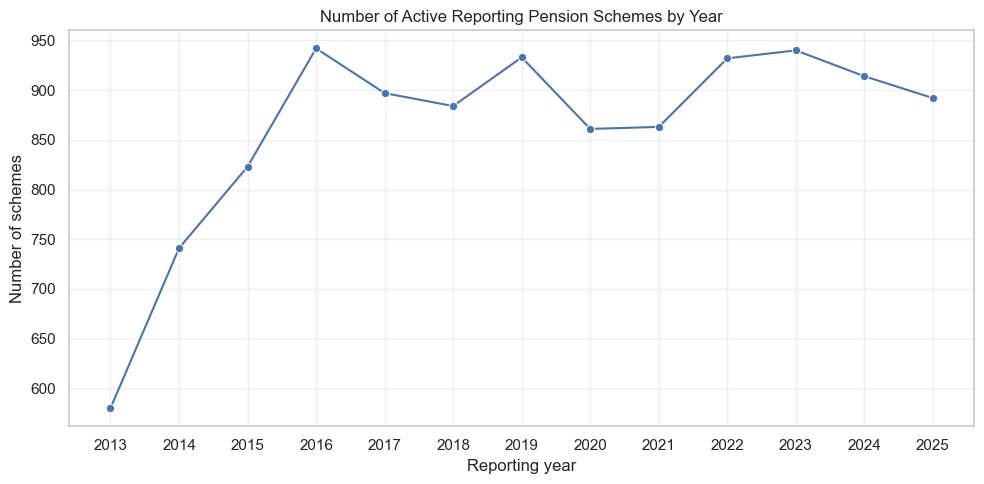

In [30]:
plt.figure(figsize=(10, 5))
sns.lineplot(
    data=annual_coverage,
    x="Year",
    y="Unique_Schemes",
    marker="o"
)
plt.title("Number of Active Reporting Pension Schemes by Year")
plt.xlabel("Reporting year")
plt.ylabel("Number of schemes")
plt.xticks(annual_coverage["Year"])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 6.2 Industry-weighted asset allocation by year

In [31]:
annual_asset_totals = eda_data.groupby("Year")[asset_columns].sum()
annual_total_investments = annual_asset_totals.sum(axis=1)

annual_industry_shares = (
    annual_asset_totals.div(annual_total_investments, axis=0) * 100
)

asset_label_mapping = {
    "Cash, Demand & Fixed Deposits": "Cash and Deposits",
    "Commercial Paper and Corporate Bonds": "Corporate Bonds",
    "Guaranteed Funds": "Guaranteed Funds",
    "Immovable Property": "Immovable Property",
    "Kenya Government Securities": "Government Securities",
    "Offshore Investments": "Offshore Investments",
    "Property Unit Trusts": "Property Unit Trusts",
    "Quoted Equity": "Quoted Equity",
    "Unquoted Equity": "Unquoted Equity"
}

annual_industry_shares = annual_industry_shares.rename(columns=asset_label_mapping)
display(annual_industry_shares.round(2))

,Cash and Deposits,Corporate Bonds,Guaranteed Funds,Immovable Property,Government Securities,Offshore Investments,Property Unit Trusts,Quoted Equity,Unquoted Equity
Year,,,,,,,,,
2013,4.6800,4.7300,31.8500,10.3500,26.4300,1.9000,0.0500,18.9500,1.0700
2014,4.4000,5.4500,32.9000,8.8900,25.1000,2.2900,0.2800,19.9500,0.7400
2015,7.4100,5.7500,24.8400,10.4000,29.0500,1.6900,1.0500,19.6100,0.2200
2016,4.1200,4.9700,19.7800,17.8400,35.9200,0.7700,0.3700,15.3000,0.9300
2017,3.9800,3.8000,20.7300,17.8100,34.9400,1.2000,0.3200,16.4500,0.7700
2018,3.9600,2.7000,20.0400,21.7600,33.9500,1.0700,0.9900,14.9800,0.5500
2019,3.9800,2.1500,20.4800,19.3000,37.6700,0.5200,0.3700,14.7600,0.7600
2020,3.8500,0.7000,23.7500,19.7000,38.1600,0.8400,0.0500,12.5300,0.4400
2021,2.8900,0.4200,23.2500,16.5500,40.4300,1.1600,0.2900,14.3400,0.6900


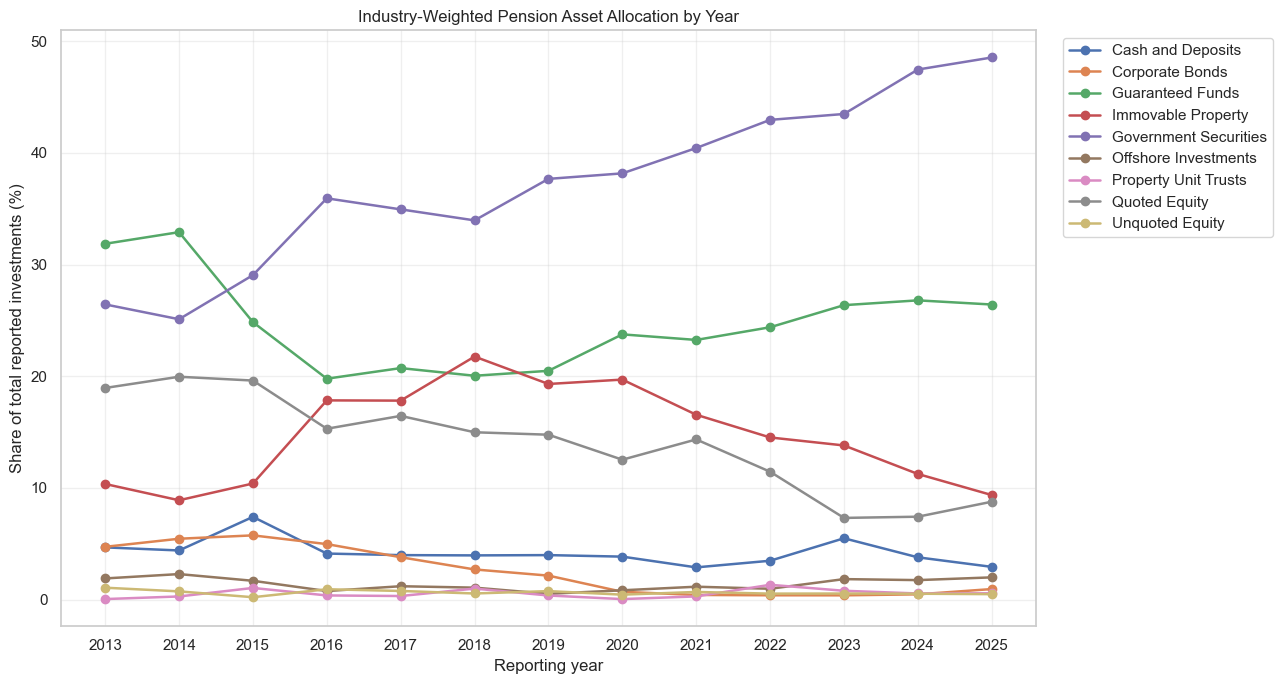

In [32]:
plt.figure(figsize=(13, 7))
for column in annual_industry_shares.columns:
    plt.plot(
        annual_industry_shares.index,
        annual_industry_shares[column],
        marker="o",
        linewidth=1.8,
        label=column
    )
plt.title("Industry-Weighted Pension Asset Allocation by Year")
plt.xlabel("Reporting year")
plt.ylabel("Share of total reported investments (%)")
plt.xticks(annual_industry_shares.index)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 6.3 Dominant asset-class distribution

,Dominant_Asset_Class,Observations,Percentage
0,Guaranteed Funds,7473,66.7113
1,Kenya Government Securities,3283,29.3073
2,Immovable Property,209,1.8657
3,"Cash, Demand & Fixed Deposits",103,0.9195
4,Quoted Equity,50,0.4463
5,Property Unit Trusts,32,0.2857
6,Commercial Paper and Corporate Bonds,30,0.2678
7,Offshore Investments,12,0.1071
8,Unquoted Equity,10,0.0893


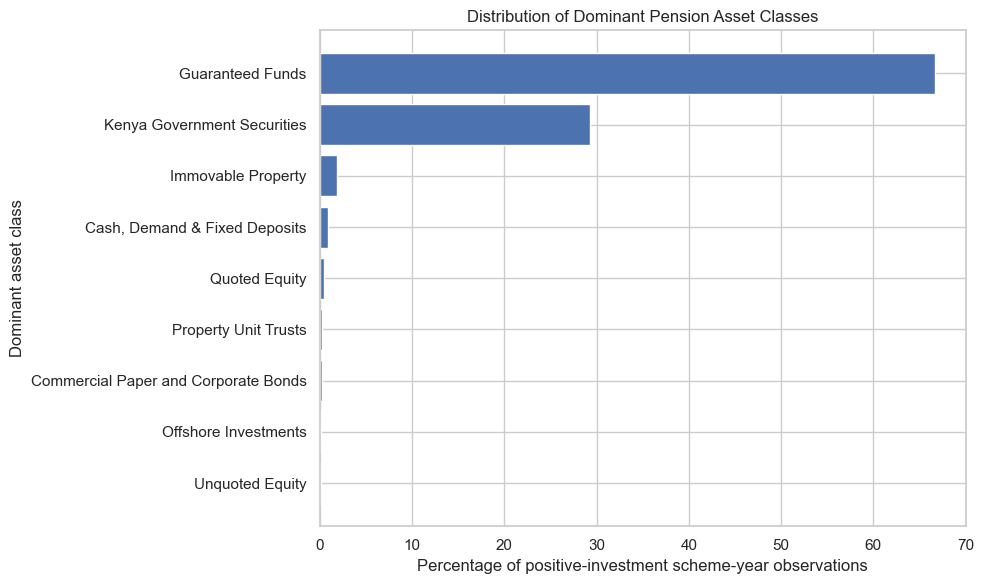

In [33]:
dominant_summary = (
    eda_data["Dominant_Asset_Class"]
    .value_counts()
    .rename_axis("Dominant_Asset_Class")
    .reset_index(name="Observations")
)
dominant_summary["Percentage"] = (
    100 * dominant_summary["Observations"] / len(eda_data)
)
display(dominant_summary)

plot_dominant = dominant_summary.sort_values("Percentage", ascending=True)
plt.figure(figsize=(10, 6))
plt.barh(plot_dominant["Dominant_Asset_Class"], plot_dominant["Percentage"])
plt.xlabel("Percentage of positive-investment scheme-year observations")
plt.ylabel("Dominant asset class")
plt.title("Distribution of Dominant Pension Asset Classes")
plt.tight_layout()
plt.show()

### 6.4 Portfolio concentration and diversification

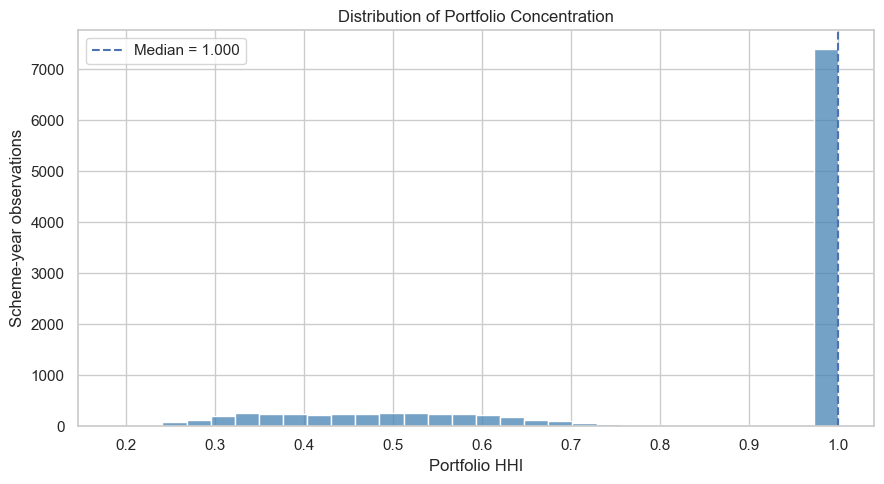

,Year,Observations,Median_HHI,Mean_HHI,Median_Diversification,Mean_Diversification,Median_Active_Classes,Mean_Active_Classes
0,2013,580,1.0000,0.8530,0.0000,0.1470,1.0000,1.8570
1,2014,741,1.0000,0.8240,0.0000,0.1760,1.0000,2.0190
2,2015,823,1.0000,0.8120,0.0000,0.1880,1.0000,2.0840
3,2016,942,1.0000,0.8040,0.0000,0.1960,1.0000,2.2460
4,2017,897,1.0000,0.8160,0.0000,0.1840,1.0000,2.1830
5,2018,884,1.0000,0.8180,0.0000,0.1820,1.0000,2.1900
6,2019,933,1.0000,0.8090,0.0000,0.1910,1.0000,2.3070
7,2020,861,1.0000,0.8440,0.0000,0.1560,1.0000,2.0360
8,2021,863,1.0000,0.8450,0.0000,0.1550,1.0000,2.1460
9,2022,932,1.0000,0.8310,0.0000,0.1690,1.0000,2.3130


In [34]:
plt.figure(figsize=(9, 5))
sns.histplot(eda_data["Portfolio_HHI"], bins=30, color="steelblue", edgecolor="white")
plt.axvline(
    eda_data["Portfolio_HHI"].median(),
    linestyle="--",
    label=f"Median = {eda_data['Portfolio_HHI'].median():.3f}"
)
plt.xlabel("Portfolio HHI")
plt.ylabel("Scheme-year observations")
plt.title("Distribution of Portfolio Concentration")
plt.legend()
plt.tight_layout()
plt.show()

annual_portfolio_structure = (
    eda_data.groupby("Year")
    .agg(
        Observations=("Ref", "size"),
        Median_HHI=("Portfolio_HHI", "median"),
        Mean_HHI=("Portfolio_HHI", "mean"),
        Median_Diversification=("Diversification_Index", "median"),
        Mean_Diversification=("Diversification_Index", "mean"),
        Median_Active_Classes=("Active_Asset_Classes", "median"),
        Mean_Active_Classes=("Active_Asset_Classes", "mean")
    )
    .reset_index()
)

display(annual_portfolio_structure.round(3))

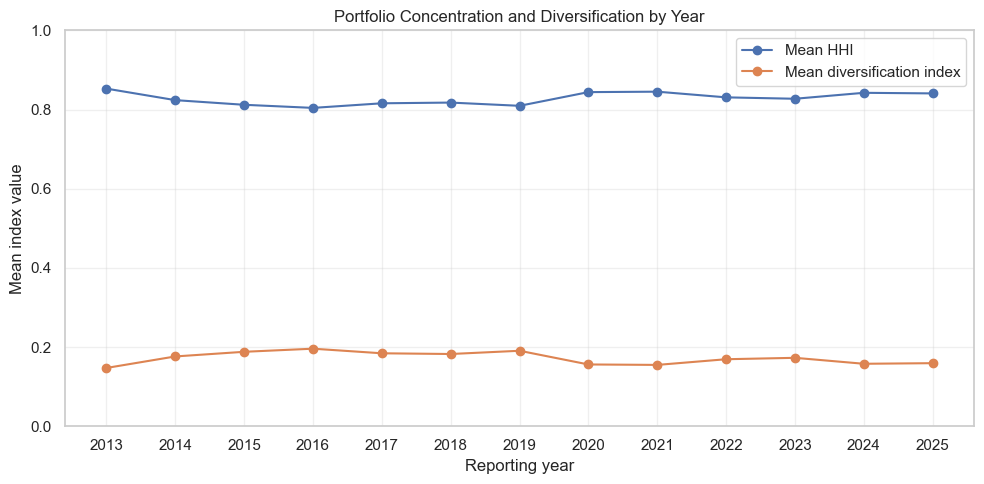

In [35]:
plt.figure(figsize=(10, 5))
plt.plot(
    annual_portfolio_structure["Year"],
    annual_portfolio_structure["Mean_HHI"],
    marker="o",
    label="Mean HHI"
)
plt.plot(
    annual_portfolio_structure["Year"],
    annual_portfolio_structure["Mean_Diversification"],
    marker="o",
    label="Mean diversification index"
)
plt.xlabel("Reporting year")
plt.ylabel("Mean index value")
plt.title("Portfolio Concentration and Diversification by Year")
plt.xticks(annual_portfolio_structure["Year"])
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 7. Descriptive analysis: portfolio transitions

The transition analysis examines consecutive-year movements from the previous reporting year to the current reporting year. It distinguishes the largest increase in any asset-class share from overall portfolio turnover.

### 7.1 Calculate transition magnitude and apply the descriptive 5-percentage-point definition

In [36]:
transition_analysis = df_transitions.copy()

change_name_mapping = {
    f"Change_{share_column}": asset_column
    for asset_column, share_column in share_mapping.items()
}
transition_change_columns = list(change_name_mapping.keys())

transition_analysis["Allocation_Turnover"] = (
    0.5 * transition_analysis[transition_change_columns].abs().sum(axis=1)
)
transition_analysis["Maximum_Asset_Class_Change"] = (
    transition_analysis[transition_change_columns].abs().max(axis=1)
)
transition_analysis["Material_Change_5pct"] = (
    transition_analysis["Maximum_Asset_Class_Change"] >= 0.05
).astype(int)

transition_analysis["Largest_Increase_Class"] = (
    transition_analysis[transition_change_columns].idxmax(axis=1).map(change_name_mapping)
)
transition_analysis["Largest_Increase_Size"] = (
    transition_analysis[transition_change_columns].max(axis=1)
)
transition_analysis["Largest_Decrease_Class"] = (
    transition_analysis[transition_change_columns].idxmin(axis=1).map(change_name_mapping)
)
transition_analysis["Largest_Decrease_Size"] = (
    transition_analysis[transition_change_columns].min(axis=1)
)

material_transitions = transition_analysis.loc[
    transition_analysis["Material_Change_5pct"].eq(1)
].copy()

print("All consecutive-year transitions:", len(transition_analysis))
print("Material transitions (at least 5 pp in one asset class):", len(material_transitions))
print("Material transition rate (%):", round(100 * transition_analysis["Material_Change_5pct"].mean(), 2))
print(
    "Median maximum individual asset-class change among material transitions (pp):",
    round(100 * material_transitions["Maximum_Asset_Class_Change"].median(), 2)
)
print(
    "Median overall portfolio turnover among material transitions (pp):",
    round(100 * material_transitions["Allocation_Turnover"].median(), 2)
)

All consecutive-year transitions: 9597
Material transitions (at least 5 pp in one asset class): 2123
Material transition rate (%): 22.12
Median maximum individual asset-class change among material transitions (pp): 9.95
Median overall portfolio turnover among material transitions (pp): 11.06


### 7.2 Summarise the largest increases and decreases

In [37]:
largest_increases_summary = (
    material_transitions.groupby("Largest_Increase_Class")
    .agg(
        Number_of_Transitions=("Ref", "size"),
        Number_of_Schemes=("Ref", "nunique"),
        Median_Increase=("Largest_Increase_Size", "median"),
        Mean_Increase=("Largest_Increase_Size", "mean")
    )
    .sort_values("Number_of_Transitions", ascending=False)
    .reset_index()
)
largest_increases_summary["Percentage_of_Material_Transitions"] = (
    100 * largest_increases_summary["Number_of_Transitions"] / len(material_transitions)
)
largest_increases_summary["Median_Increase_pp"] = 100 * largest_increases_summary["Median_Increase"]
largest_increases_summary["Mean_Increase_pp"] = 100 * largest_increases_summary["Mean_Increase"]

display(largest_increases_summary[[
    "Largest_Increase_Class", "Number_of_Transitions", "Number_of_Schemes",
    "Percentage_of_Material_Transitions", "Median_Increase_pp", "Mean_Increase_pp"
]])

largest_decreases_summary = (
    material_transitions.groupby("Largest_Decrease_Class")
    .agg(
        Number_of_Transitions=("Ref", "size"),
        Number_of_Schemes=("Ref", "nunique"),
        Median_Decrease=("Largest_Decrease_Size", "median"),
        Mean_Decrease=("Largest_Decrease_Size", "mean")
    )
    .sort_values("Number_of_Transitions", ascending=False)
    .reset_index()
)
largest_decreases_summary["Percentage_of_Material_Transitions"] = (
    100 * largest_decreases_summary["Number_of_Transitions"] / len(material_transitions)
)
largest_decreases_summary["Median_Decrease_pp"] = 100 * largest_decreases_summary["Median_Decrease"]
largest_decreases_summary["Mean_Decrease_pp"] = 100 * largest_decreases_summary["Mean_Decrease"]

display(largest_decreases_summary[[
    "Largest_Decrease_Class", "Number_of_Transitions", "Number_of_Schemes",
    "Percentage_of_Material_Transitions", "Median_Decrease_pp", "Mean_Decrease_pp"
]])

,Largest_Increase_Class,Number_of_Transitions,Number_of_Schemes,Percentage_of_Material_Transitions,Median_Increase_pp,Mean_Increase_pp
0,Kenya Government Securities,979,370,46.1140,9.2585,15.0378
1,"Cash, Demand & Fixed Deposits",476,287,22.4211,7.4555,12.8379
2,Quoted Equity,228,167,10.7395,6.8455,10.5954
3,Guaranteed Funds,168,118,7.9133,30.7112,48.0233
4,Immovable Property,126,67,5.9350,10.8374,21.6907
5,Commercial Paper and Corporate Bonds,63,53,2.9675,12.4785,26.7219
6,Offshore Investments,35,32,1.6486,5.7496,8.7981
7,Property Unit Trusts,33,30,1.5544,24.9788,35.4681
8,Unquoted Equity,15,14,0.7065,23.5448,35.1230


,Largest_Decrease_Class,Number_of_Transitions,Number_of_Schemes,Percentage_of_Material_Transitions,Median_Decrease_pp,Mean_Decrease_pp
0,"Cash, Demand & Fixed Deposits",582,316,27.4140,-8.2400,-14.0256
1,Quoted Equity,555,300,26.1423,-6.4847,-8.6748
2,Kenya Government Securities,545,314,25.6712,-9.5542,-19.7823
3,Guaranteed Funds,133,69,6.2647,-27.5782,-39.9916
4,Immovable Property,110,68,5.1813,-11.0331,-21.3939
5,Commercial Paper and Corporate Bonds,97,76,4.5690,-7.9488,-18.1472
6,Offshore Investments,50,39,2.3552,-5.7561,-7.9316
7,Property Unit Trusts,40,38,1.8841,-31.4233,-43.4552
8,Unquoted Equity,11,10,0.5181,-23.5448,-38.2786


### 7.3 Examine the most common asset-class transition pairs

In [38]:
transition_pairs = (
    material_transitions.groupby(["Largest_Decrease_Class", "Largest_Increase_Class"])
    .agg(
        Number_of_Transitions=("Ref", "size"),
        Number_of_Schemes=("Ref", "nunique"),
        Median_Turnover=("Allocation_Turnover", "median"),
        Mean_Turnover=("Allocation_Turnover", "mean")
    )
    .reset_index()
)
transition_pairs["Median_Turnover_pp"] = 100 * transition_pairs["Median_Turnover"]
transition_pairs["Mean_Turnover_pp"] = 100 * transition_pairs["Mean_Turnover"]
transition_pairs = transition_pairs.sort_values(
    "Number_of_Transitions", ascending=False
).reset_index(drop=True)

display(transition_pairs[[
    "Largest_Decrease_Class", "Largest_Increase_Class", "Number_of_Transitions",
    "Number_of_Schemes", "Median_Turnover_pp", "Mean_Turnover_pp"
]].head(20))

,Largest_Decrease_Class,Largest_Increase_Class,Number_of_Transitions,Number_of_Schemes,Median_Turnover_pp,Mean_Turnover_pp
0,"Cash, Demand & Fixed Deposits",Kenya Government Securities,436,258,11.7709,16.3157
1,Quoted Equity,Kenya Government Securities,300,197,8.6789,11.6032
2,Kenya Government Securities,"Cash, Demand & Fixed Deposits",230,174,10.3498,15.6185
3,Quoted Equity,"Cash, Demand & Fixed Deposits",177,140,8.1275,10.1426
4,Kenya Government Securities,Guaranteed Funds,106,84,42.1295,52.5611
5,Kenya Government Securities,Quoted Equity,105,89,9.7694,14.1980
6,Guaranteed Funds,Kenya Government Securities,91,45,31.9487,39.2105
7,"Cash, Demand & Fixed Deposits",Quoted Equity,80,75,8.4043,10.0174
8,Immovable Property,Kenya Government Securities,68,50,13.3935,21.9220
9,Kenya Government Securities,Immovable Property,58,43,14.9293,27.6164


### 7.4 Review displacement when major asset classes increase

In [39]:
government_increase_transitions = material_transitions.loc[
    material_transitions["Largest_Increase_Class"].eq("Kenya Government Securities")
].copy()

government_displacement = (
    government_increase_transitions["Largest_Decrease_Class"]
    .value_counts()
    .rename_axis("Asset_Class_Reduced")
    .reset_index(name="Number_of_Transitions")
)
if len(government_increase_transitions) > 0:
    government_displacement["Percentage"] = (
        100 * government_displacement["Number_of_Transitions"]
        / len(government_increase_transitions)
    )
else:
    government_displacement["Percentage"] = pd.Series(dtype=float)

print("Material transitions where Government Securities had the largest increase:", len(government_increase_transitions))
display(government_displacement)


guaranteed_increase_transitions = material_transitions.loc[
    material_transitions["Largest_Increase_Class"].eq("Guaranteed Funds")
].copy()

guaranteed_displacement = (
    guaranteed_increase_transitions["Largest_Decrease_Class"]
    .value_counts()
    .rename_axis("Asset_Class_Reduced")
    .reset_index(name="Number_of_Transitions")
)
if len(guaranteed_increase_transitions) > 0:
    guaranteed_displacement["Percentage"] = (
        100 * guaranteed_displacement["Number_of_Transitions"]
        / len(guaranteed_increase_transitions)
    )
else:
    guaranteed_displacement["Percentage"] = pd.Series(dtype=float)

print("Material transitions where Guaranteed Funds had the largest increase:", len(guaranteed_increase_transitions))
display(guaranteed_displacement)

Material transitions where Government Securities had the largest increase: 979


,Asset_Class_Reduced,Number_of_Transitions,Percentage
0,"Cash, Demand & Fixed Deposits",436,44.5352
1,Quoted Equity,300,30.6435
2,Guaranteed Funds,91,9.2952
3,Immovable Property,68,6.9459
4,Commercial Paper and Corporate Bonds,47,4.8008
5,Offshore Investments,26,2.6558
6,Property Unit Trusts,9,0.9193
7,Unquoted Equity,2,0.2043


Material transitions where Guaranteed Funds had the largest increase: 168


,Asset_Class_Reduced,Number_of_Transitions,Percentage
0,Kenya Government Securities,106,63.0952
1,"Cash, Demand & Fixed Deposits",25,14.8810
2,Quoted Equity,19,11.3095
3,Immovable Property,9,5.3571
4,Commercial Paper and Corporate Bonds,4,2.3810
5,Unquoted Equity,3,1.7857
6,Property Unit Trusts,2,1.1905


### 7.5 Visualise transition pairs

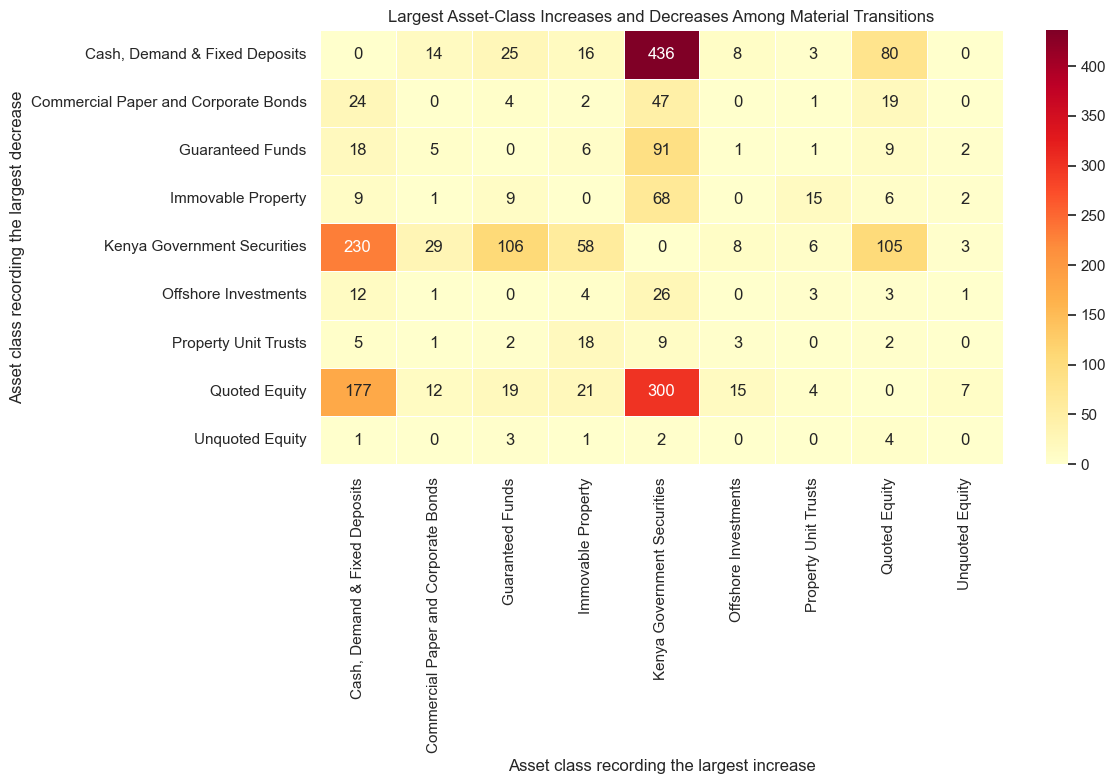

In [40]:
transition_matrix = pd.pivot_table(
    transition_pairs,
    index="Largest_Decrease_Class",
    columns="Largest_Increase_Class",
    values="Number_of_Transitions",
    aggfunc="sum",
    fill_value=0
)

plt.figure(figsize=(12, 8))
sns.heatmap(transition_matrix, annot=True, fmt=".0f", cmap="YlOrRd", linewidths=0.5)
plt.title("Largest Asset-Class Increases and Decreases Among Material Transitions")
plt.xlabel("Asset class recording the largest increase")
plt.ylabel("Asset class recording the largest decrease")
plt.tight_layout()
plt.show()

### 7.6 Examine material transition rates over time

,Year,Consecutive_Transitions,Material_Transitions,Median_Turnover,Material_Change_Rate,Median_Turnover_pp
0,2014,467,80,0.0000,17.1300,0.0000
1,2015,659,155,0.0000,23.5200,0.0000
2,2016,783,232,0.0000,29.6300,0.0000
3,2017,840,194,0.0000,23.1000,0.0000
4,2018,844,180,0.0000,21.3300,0.0000
5,2019,832,203,0.0000,24.4000,0.0000
6,2020,826,174,0.0000,21.0700,0.0000
7,2021,832,131,0.0000,15.7500,0.0000
8,2022,824,148,0.0000,17.9600,0.0000
9,2023,901,243,0.0000,26.9700,0.0000


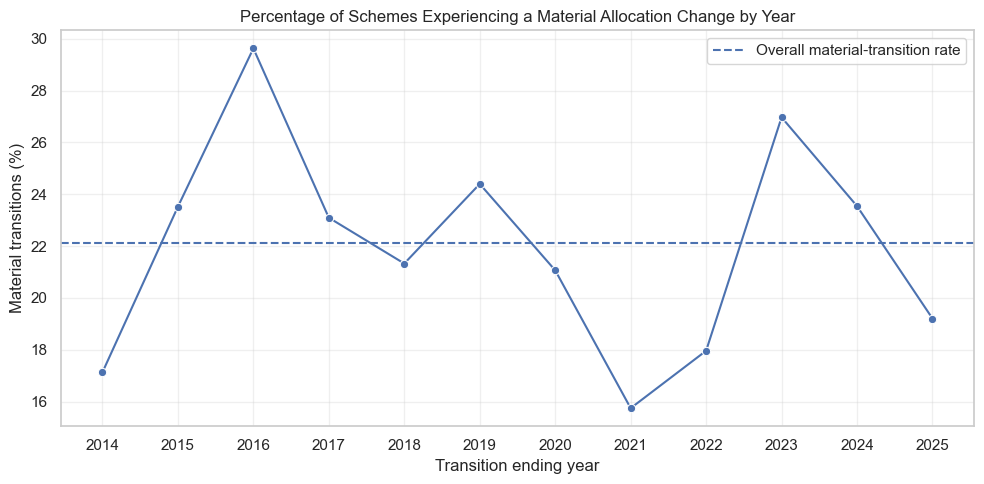

In [41]:
annual_material_changes = (
    transition_analysis.groupby("Year")
    .agg(
        Consecutive_Transitions=("Ref", "size"),
        Material_Transitions=("Material_Change_5pct", "sum"),
        Median_Turnover=("Allocation_Turnover", "median")
    )
    .reset_index()
)

annual_material_changes["Material_Change_Rate"] = (
    100 * annual_material_changes["Material_Transitions"]
    / annual_material_changes["Consecutive_Transitions"]
)
annual_material_changes["Median_Turnover_pp"] = 100 * annual_material_changes["Median_Turnover"]

display(annual_material_changes.round(2))

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=annual_material_changes,
    x="Year",
    y="Material_Change_Rate",
    marker="o"
)
plt.axhline(
    transition_analysis["Material_Change_5pct"].mean() * 100,
    linestyle="--",
    label="Overall material-transition rate"
)
plt.xlabel("Transition ending year")
plt.ylabel("Material transitions (%)")
plt.title("Percentage of Schemes Experiencing a Material Allocation Change by Year")
plt.xticks(annual_material_changes["Year"])
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 8. Prepare the binary classification target and predictor features

The prediction task is to estimate, using information available for scheme-year *t*, whether at least one asset-class share will change by five percentage points or more in the following consecutive reporting year *t + 1*.

For consistency with the existing analysis, the classification dataset requires both:

- a consecutive previous year, so the historical change predictors are available; and
- a consecutive following year, so the future outcome can be measured.

This intentionally excludes scheme-years without a valid consecutive observation on either side. The target is based on the **largest absolute change in any individual asset-class share**, not on overall portfolio turnover.

### 8.1 Identify the following reporting year and future asset shares

In [42]:
# These lead variables are used only to construct the future outcome.
# They must not be included among model predictors.
df_modelling["Next_Year"] = df_modelling.groupby("Ref")["Year"].shift(-1)
df_modelling["Next_Year_Consecutive"] = (
    df_modelling["Next_Year"] - df_modelling["Year"]
).eq(1)

future_share_columns = []
for share_column in share_columns:
    future_column = f"Next_{share_column}"
    future_share_columns.append(future_column)
    df_modelling[future_column] = df_modelling.groupby("Ref")[share_column].shift(-1)
    df_modelling.loc[~df_modelling["Next_Year_Consecutive"], future_column] = np.nan

print("Scheme-years with a consecutive following year:", int(df_modelling["Next_Year_Consecutive"].sum()))

Scheme-years with a consecutive following year: 9597


### 8.2 Calculate future allocation changes and materiality measures

In [43]:
# Attach next-year information to the existing transition table without
# rebuilding it, so the previously calculated historical transition features remain.
df_transitions["Next_Year"] = df_modelling["Next_Year"].reindex(df_transitions.index)
df_transitions["Next_Year_Consecutive"] = (
    df_modelling["Next_Year_Consecutive"].reindex(df_transitions.index)
)
for future_share in future_share_columns:
    df_transitions[future_share] = df_modelling[future_share].reindex(df_transitions.index)

absolute_future_changes = pd.DataFrame(index=df_transitions.index)
for current_share, future_share in zip(share_columns, future_share_columns):
    absolute_future_changes[current_share] = (
        df_transitions[future_share] - df_transitions[current_share]
    ).abs()

df_transitions["Maximum_Future_Asset_Class_Change"] = absolute_future_changes.max(
    axis=1,
    skipna=False
)
df_transitions["Future_Allocation_Turnover"] = (
    0.5 * absolute_future_changes.sum(axis=1, min_count=len(share_columns))
)

print("Rows with a consecutive previous year:", len(df_transitions))
print("Rows also having a consecutive following year:", int(df_transitions["Next_Year_Consecutive"].sum()))
print("Rows missing the complete future change measure:", int(df_transitions["Maximum_Future_Asset_Class_Change"].isna().sum()))

Rows with a consecutive previous year: 9597
Rows also having a consecutive following year: 8330
Rows missing the complete future change measure: 1267


### 8.3 Construct the binary target using the 5-percentage-point threshold

In [44]:
MATERIAL_CHANGE_THRESHOLD = 0.05
classification_target = "Material_Allocation_Change_Next_Year"

df_classification_ready = df_transitions.loc[
    df_transitions["Next_Year_Consecutive"]
    & df_transitions["Maximum_Future_Asset_Class_Change"].notna()
].copy()

df_classification_ready[classification_target] = (
    df_classification_ready["Maximum_Future_Asset_Class_Change"]
    >= MATERIAL_CHANGE_THRESHOLD
).astype("int8")

# Add scale-related predictors based only on current and previous-year information.
df_classification_ready["Log_Total_Investments"] = np.log1p(
    df_classification_ready["Total_Investments"]
)
df_classification_ready["Log_Portfolio_Growth"] = np.log(
    df_classification_ready["Total_Investments"]
    / df_classification_ready["Previous_Total_Investments"]
)

df_classification_ready["Dominant_Class_Changed"] = (
    df_classification_ready["Dominant_Class_Changed"].astype("int8")
)

print("Classification-ready observations:", len(df_classification_ready))
print("Unique schemes:", df_classification_ready["Ref"].nunique())
print("Missing target values:", df_classification_ready[classification_target].isna().sum())

display(df_classification_ready[classification_target].value_counts().sort_index().rename(index={0: "No material change", 1: "Material change"}).to_frame("Observations"))

Classification-ready observations: 8330
Unique schemes: 1081
Missing target values: 0


,Observations
Material_Allocation_Change_Next_Year,
No material change,6567
Material change,1763


### 8.4 Inspect class balance

The target is expected to be imbalanced because material changes are less frequent than non-material changes. This is documented here; any class weighting or resampling decision belongs to the modelling stage and must be fitted using training data only.

In [45]:
class_counts = df_classification_ready[classification_target].value_counts().sort_index()
class_percentages = (
    df_classification_ready[classification_target]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

class_balance = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percentages
}).rename(index={0: "No material change (0)", 1: "Material change (1)"})

display(class_balance.round(2))

,Count,Percentage
Material_Allocation_Change_Next_Year,,
No material change (0),6567,78.8400
Material change (1),1763,21.1600


### 8.5 Define the predictor set and audit it for missing or infinite values

The predictor list includes current asset shares, historical year-on-year changes, current concentration and portfolio structure, historical concentration change, dominant-class change, portfolio size/growth and reporting year. `Dominant_Asset_Class` is the single categorical predictor.

Future shares, future allocation changes, the target and any target-construction variables are deliberately excluded from the predictor list.

In [46]:
classification_numeric_features = (
    share_columns
    + change_columns
    + [
        "Portfolio_HHI",
        "Active_Asset_Classes",
        "HHI_Change",
        "Dominant_Class_Changed",
        "Log_Total_Investments",
        "Log_Portfolio_Growth",
        "Year"
    ]
)

classification_categorical_features = ["Dominant_Asset_Class"]
classification_features = (
    classification_numeric_features + classification_categorical_features
)

missing_predictors = df_classification_ready[classification_features].isna().sum()
missing_predictors = missing_predictors.loc[missing_predictors > 0]

numeric_predictor_values = df_classification_ready[classification_numeric_features]
infinite_predictors = pd.Series(
    np.isinf(numeric_predictor_values.to_numpy()).sum(axis=0),
    index=classification_numeric_features
)
infinite_predictors = infinite_predictors.loc[infinite_predictors > 0]

print("Number of predictors:", len(classification_features))
print("Missing predictor columns:")
display(missing_predictors.to_frame("Missing values"))
print("Predictor columns containing infinity:")
display(infinite_predictors.to_frame("Infinite values"))

# Explicitly check that target/future fields are not part of the predictor list.
forbidden_predictor_terms = ["next_", "future", "target", "material_allocation"]
suspicious_predictors = [
    feature for feature in classification_features
    if any(term in feature.lower() for term in forbidden_predictor_terms)
]
print("Predictor names containing future/target terms:", suspicious_predictors)

assert len(classification_features) == 26
assert missing_predictors.empty
assert infinite_predictors.empty
assert not suspicious_predictors

Number of predictors: 26
Missing predictor columns:


,Missing values


Predictor columns containing infinity:


,Infinite values


Predictor names containing future/target terms: []


## 9. Expanding-window temporal validation and final chronological partitions

Model comparison uses **expanding-window temporal validation** across three successive outcome years: 2020, 2021 and 2022. For each fold, the model is trained only on earlier outcome years and evaluated on the next year:

- Fold 1: train on outcomes through 2019; validate on outcome year 2020.
- Fold 2: train on outcomes through 2020; validate on outcome year 2021.
- Fold 3: train on outcomes through 2021; validate on outcome year 2022.

After selecting the model using the **mean validation Average Precision (PR-AUC)** across these folds, the selected candidate (and the other candidates for descriptive comparison) is refitted on all observations with outcomes through 2022.

Outcome year 2023 is kept separate and used only to fit the sigmoid probability calibrator. The calibrated model uses a pre-specified probability threshold of 0.50; the 2023 calibration outcomes are not also used to optimise a classification threshold. Outcomes in 2024–2025 form the untouched final test period.

The chronological design allows the same scheme to appear in different years. Therefore, results estimate future-year performance for schemes with historical records; they do not estimate performance on entirely unseen schemes.

### 9.1 Define expanding-window folds and final model-use periods

In [47]:
# Outcome years are used for splitting because the model predicts Next_Year.
TEMPORAL_CV_YEARS = [2020, 2021, 2022]
CALIBRATION_OUTCOME_YEAR = 2023
TEST_OUTCOME_YEARS = [2024, 2025]

# Final estimator-training data: all labelled observations available before calibration.
train_classification = df_classification_ready.loc[
    df_classification_ready["Next_Year"] <= 2022
].copy()

# Separate calibration and final test periods.
calibration_classification = df_classification_ready.loc[
    df_classification_ready["Next_Year"] == CALIBRATION_OUTCOME_YEAR
].copy()
test_classification = df_classification_ready.loc[
    df_classification_ready["Next_Year"].isin(TEST_OUTCOME_YEARS)
].copy()

# Construct expanding-window folds. Each validation year is strictly later than
# every outcome year used to fit that fold's model.
temporal_cv_folds = []
fold_summary_rows = []

for validation_year in TEMPORAL_CV_YEARS:
    fold_train = df_classification_ready.loc[
        df_classification_ready["Next_Year"] < validation_year
    ].copy()
    fold_validation = df_classification_ready.loc[
        df_classification_ready["Next_Year"] == validation_year
    ].copy()

    if fold_train.empty or fold_validation.empty:
        raise ValueError(f"Temporal fold for {validation_year} has an empty partition.")
    if fold_train[classification_target].nunique() != 2:
        raise ValueError(f"Training data before {validation_year} do not contain both target classes.")
    if fold_validation[classification_target].nunique() != 2:
        raise ValueError(f"Validation year {validation_year} does not contain both target classes.")
    if fold_train["Next_Year"].max() >= fold_validation["Next_Year"].min():
        raise AssertionError("Temporal leakage detected between a fold's training and validation periods.")

    temporal_cv_folds.append({
        "validation_outcome_year": validation_year,
        "train": fold_train,
        "validation": fold_validation,
    })
    fold_summary_rows.append({
        "Fold": f"Train through {validation_year - 1}; validate {validation_year}",
        "Training_Observations": len(fold_train),
        "Training_Outcome_Year_Min": int(fold_train["Next_Year"].min()),
        "Training_Outcome_Year_Max": int(fold_train["Next_Year"].max()),
        "Training_Positive_Count": int(fold_train[classification_target].sum()),
        "Validation_Observations": len(fold_validation),
        "Validation_Positive_Count": int(fold_validation[classification_target].sum()),
        "Validation_Negative_Count": int((fold_validation[classification_target] == 0).sum()),
        "Validation_Positive_Rate": float(fold_validation[classification_target].mean()),
    })

temporal_cv_fold_summary = pd.DataFrame(fold_summary_rows)
print("Expanding-window validation folds:")
display(temporal_cv_fold_summary.round(4))

# Validate final chronological partitions.
final_partition_summary = []
for partition_name, partition_data in {
    "Final model training": train_classification,
    "Probability calibration": calibration_classification,
    "Final testing": test_classification,
}.items():
    final_partition_summary.append({
        "Partition": partition_name,
        "Observations": len(partition_data),
        "Outcome_Year_Min": int(partition_data["Next_Year"].min()),
        "Outcome_Year_Max": int(partition_data["Next_Year"].max()),
        "Non_Material_Count": int((partition_data[classification_target] == 0).sum()),
        "Material_Count": int(partition_data[classification_target].sum()),
        "Material_Percentage": float(partition_data[classification_target].mean() * 100),
    })
final_partition_summary = pd.DataFrame(final_partition_summary)
print("Final model-use partitions:")
display(final_partition_summary.round(2))

assert len(train_classification) + len(calibration_classification) + len(test_classification) == len(df_classification_ready)
assert train_classification["Next_Year"].max() < calibration_classification["Next_Year"].min()
assert calibration_classification["Next_Year"].max() < test_classification["Next_Year"].min()
assert set(train_classification["Next_Year"].unique()).issubset(set(range(2015, 2023)))
assert calibration_classification["Next_Year"].nunique() == 1
assert calibration_classification["Next_Year"].iloc[0] == CALIBRATION_OUTCOME_YEAR
assert set(test_classification["Next_Year"].unique()).issubset(set(TEST_OUTCOME_YEARS))

print("Temporal fold and final partition checks: PASSED.")

Expanding-window validation folds:


,Fold,Training_Observations,Training_Outcome_Year_Min,Training_Outcome_Year_Max,Training_Positive_Count,Validation_Observations,Validation_Positive_Count,Validation_Negative_Count,Validation_Positive_Rate
0,Train through 2019; validate 2020,3393,2015,2019,764,793,164,629,0.2068
1,Train through 2020; validate 2021,4186,2015,2020,928,799,126,673,0.1577
2,Train through 2021; validate 2022,4985,2015,2021,1054,799,140,659,0.1752


Final model-use partitions:


,Partition,Observations,Outcome_Year_Min,Outcome_Year_Max,Non_Material_Count,Material_Count,Material_Percentage
0,Final model training,5784,2015,2022,4590,1194,20.6400
1,Probability calibration,799,2023,2023,601,198,24.7800
2,Final testing,1747,2024,2025,1376,371,21.2400


Temporal fold and final partition checks: PASSED.


### 9.2 Check scheme overlap across the final chronological partitions

In [48]:
# Scheme overlap is expected for this forecasting task: the intended use is to
# predict future outcomes for schemes with available historical information.
train_schemes = set(train_classification["Ref"])
calibration_schemes = set(calibration_classification["Ref"])
test_schemes = set(test_classification["Ref"])

scheme_overlap_summary = pd.DataFrame({
    "Comparison": [
        "Final training and calibration",
        "Final training and testing",
        "Calibration and testing",
    ],
    "Overlapping_Schemes": [
        len(train_schemes & calibration_schemes),
        len(train_schemes & test_schemes),
        len(calibration_schemes & test_schemes),
    ],
})
display(scheme_overlap_summary)
print("Interpretation: scheme overlap is permitted across time; outcome-year overlap is not.")

,Comparison,Overlapping_Schemes
0,Final training and calibration,788
1,Final training and testing,801
2,Calibration and testing,776


Interpretation: scheme overlap is permitted across time; outcome-year overlap is not.


### 9.3 Prepare predictor and target objects

In [49]:
X_train = train_classification[classification_features].copy()
y_train = train_classification[classification_target].copy()

X_calibration = calibration_classification[classification_features].copy()
y_calibration = calibration_classification[classification_target].copy()

X_test = test_classification[classification_features].copy()
y_test = test_classification[classification_target].copy()

print("Final training predictors:", X_train.shape)
print("Final training target:", y_train.shape)
print("Calibration predictors:", X_calibration.shape)
print("Calibration target:", y_calibration.shape)
print("Test predictors:", X_test.shape)
print("Test target:", y_test.shape)

Final training predictors: (5784, 26)
Final training target: (5784,)
Calibration predictors: (799, 26)
Calibration target: (799,)
Test predictors: (1747, 26)
Test target: (1747,)


## 10. Final pre-modelling checkpoint

The analytical preparation is complete. Expanding-window validation will compare candidate models across outcome years 2020, 2021 and 2022. The selected model will then be refitted on all outcome years through 2022, calibrated using 2023, and assessed once on the held-out 2024–2025 test period.

In [50]:
pre_model_checkpoint = pd.Series({
    "Raw dataset rows": len(df_raw),
    "Annual scheme-year observations": len(df_annual),
    "Positive-investment scheme-year observations": len(df_modelling),
    "Valid consecutive-year transitions": len(df_transitions),
    "Classification-ready observations": len(df_classification_ready),
    "Unique schemes in classification dataset": df_classification_ready["Ref"].nunique(),
    "Predictor count": len(classification_features),
    "Expanding-window validation folds": len(temporal_cv_folds),
    "Final model-training observations (outcomes through 2022)": len(train_classification),
    "Calibration observations (outcome year 2023)": len(calibration_classification),
    "Final test observations (outcomes 2024-2025)": len(test_classification),
    "Missing predictor values": int(df_classification_ready[classification_features].isna().sum().sum()),
    "Infinite numeric predictor values": int(np.isinf(df_classification_ready[classification_numeric_features].to_numpy()).sum()),
}, name="Value").to_frame()
display(pre_model_checkpoint)

# Reproducibility assertions based on the supplied source dataset and retained methodology.
assert df_raw.shape == (16851, 25)
assert df_annual.shape == (13027, 26)
assert df_earlier_reports.shape[0] == 2082
assert len(df_missing_financial) == 52
assert len(df_negative_investment) == 1
assert len(df_nonpositive_portfolio) == 1772
assert df_modelling.shape[0] == 11202
assert len(df_transitions) == 9597
assert df_classification_ready.shape[0] == 8330
assert len(temporal_cv_folds) == 3
assert train_classification.shape[0] == 5784
assert calibration_classification.shape[0] == 799
assert test_classification.shape[0] == 1747
assert X_train.shape[1] == 26 and X_calibration.shape[1] == 26 and X_test.shape[1] == 26
assert df_classification_ready[classification_features].notna().all().all()
assert np.isfinite(df_classification_ready[classification_numeric_features].to_numpy(dtype=float)).all()
print("All pre-modelling and temporal partition checks passed for the supplied dataset.")

,Value
Raw dataset rows,16851
Annual scheme-year observations,13027
Positive-investment scheme-year observations,11202
Valid consecutive-year transitions,9597
Classification-ready observations,8330
Unique schemes in classification dataset,1081
Predictor count,26
Expanding-window validation folds,3
Final model-training observations (outcomes through 2022),5784
Calibration observations (outcome year 2023),799


All pre-modelling and temporal partition checks passed for the supplied dataset.


---

**Pre-modelling checkpoint passed.** The next section compares classifiers using multiple chronological validation years, rather than relying on a single validation year.

## 11. Machine-learning model development

### 11.1 Modelling objective and evaluation design

For each scheme-year *t*, predict whether the largest absolute change in any one of the nine asset-class shares between *t* and the next consecutive reporting year will be at least five percentage points. The positive class identifies a material allocation movement; it does **not** imply that the movement is harmful or non-compliant.

The proposed classifiers are Logistic Regression (interpretable linear baseline), Random Forest (bagged nonlinear trees) and Gradient Boosting (boosted trees). A prior-probability Dummy Classifier provides a reference benchmark. The primary model-selection metric is the **mean Average Precision (PR-AUC)** across the three expanding-window validation folds (2020–2022), because the positive class is less frequent than the negative class.

All preprocessing is fitted within each model pipeline on the training portion of the relevant fold. Class weighting is calculated separately within each training fold. After selection, the candidate models are refitted using outcomes through 2022. A sigmoid calibrator is fitted using outcome year 2023. The classification threshold is fixed at 0.50 after calibration rather than tuned on the calibration observations. Outcomes in 2024–2025 are reserved for final out-of-time testing.

### 11.2 Imports and reproducibility

In [51]:
import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve, precision_recall_curve,
    brier_score_loss, log_loss
)
from sklearn.calibration import CalibratedClassifierCV, calibration_curve

RANDOM_STATE = 42
CALIBRATED_DECISION_THRESHOLD = 0.50
print("scikit-learn version:", sklearn.__version__)
print("Expanding-window validation years:", TEMPORAL_CV_YEARS)
print("Final training / calibration / test sizes:", len(X_train), len(X_calibration), len(X_test))
print("Number of predictors:", len(classification_features))

scikit-learn version: 1.9.1
Expanding-window validation years: [2020, 2021, 2022]
Final training / calibration / test sizes: 5784 799 1747
Number of predictors: 26


### 11.3 Recheck predictors and temporal separation before fitting

In [52]:
forbidden_terms = ["next_", "future", "target", "material_allocation", "ref"]
forbidden_features = [
    feature for feature in classification_features
    if any(term in feature.lower() for term in forbidden_terms)
]
assert not forbidden_features, f"Potential leakage/identifier predictors: {forbidden_features}"
assert df_classification_ready[classification_features].notna().all().all()
assert np.isfinite(df_classification_ready[classification_numeric_features].to_numpy(dtype=float)).all()
assert set(pd.unique(y_train)) == {0, 1}
assert set(pd.unique(y_calibration)) == {0, 1}
assert set(pd.unique(y_test)) == {0, 1}

for fold in temporal_cv_folds:
    assert fold["train"]["Next_Year"].max() < fold["validation"]["Next_Year"].min()
    assert set(pd.unique(fold["train"][classification_target])) == {0, 1}
    assert set(pd.unique(fold["validation"][classification_target])) == {0, 1}

print("Predictor count:", len(classification_features))
print("Outcome-year range in final training:", int(train_classification.Next_Year.min()), "to", int(train_classification.Next_Year.max()))
print("Calibration outcome year:", int(calibration_classification.Next_Year.iloc[0]))
print("Test outcome years:", int(test_classification.Next_Year.min()), "to", int(test_classification.Next_Year.max()))
print("Leakage, missing-value, infinity and chronology checks: PASSED")

Predictor count: 26
Outcome-year range in final training: 2015 to 2022
Calibration outcome year: 2023
Test outcome years: 2024 to 2025
Leakage, missing-value, infinity and chronology checks: PASSED


### 11.4 Preprocessing pipelines

All preprocessing is included within each Scikit-learn pipeline. Numeric predictors are median-imputed; Logistic Regression additionally standardises them. Tree-based models do not require feature scaling. The categorical dominant-asset-class feature is mode-imputed and one-hot encoded. These transformations are fitted separately within each temporal fold, preventing information from a fold's validation year from influencing preprocessing.

In [53]:
try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:  # compatibility with older scikit-learn versions
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

def make_preprocessor(scale_numeric: bool):
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))
    numeric_pipeline = Pipeline(steps=numeric_steps)
    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", clone(encoder)),
    ])
    return ColumnTransformer(
        transformers=[
            ("numeric", numeric_pipeline, classification_numeric_features),
            ("categorical", categorical_pipeline, classification_categorical_features),
        ],
        remainder="drop",
    )

logistic_preprocessor = make_preprocessor(scale_numeric=True)
tree_preprocessor = make_preprocessor(scale_numeric=False)
print("Preprocessing pipelines defined.")

Preprocessing pipelines defined.


### 11.5 Define the benchmark and proposed classifiers

In [54]:
candidate_models = {
    "Logistic Regression": Pipeline(steps=[
        ("preprocessor", clone(logistic_preprocessor)),
        ("classifier", LogisticRegression(
            C=1.0, solver="lbfgs", max_iter=3000,
            class_weight="balanced", random_state=RANDOM_STATE
        )),
    ]),
    "Random Forest": Pipeline(steps=[
        ("preprocessor", clone(tree_preprocessor)),
        ("classifier", RandomForestClassifier(
            n_estimators=300, max_depth=12, min_samples_leaf=5,
            max_features=0.7, class_weight="balanced",
            random_state=RANDOM_STATE, n_jobs=-1
        )),
    ]),
    "Gradient Boosting": Pipeline(steps=[
        ("preprocessor", clone(tree_preprocessor)),
        ("classifier", GradientBoostingClassifier(
            n_estimators=150, learning_rate=0.03, max_depth=2,
            min_samples_leaf=10, subsample=0.8, random_state=RANDOM_STATE
        )),
    ]),
}
print("Candidate models:", list(candidate_models))
print("Reference benchmark: prior-probability Dummy Classifier")
print("Note: these are pre-specified candidate configurations, not an exhaustive hyperparameter search.")

Candidate models: ['Logistic Regression', 'Random Forest', 'Gradient Boosting']
Reference benchmark: prior-probability Dummy Classifier
Note: these are pre-specified candidate configurations, not an exhaustive hyperparameter search.


### 11.6 Define evaluation metrics

The proposal's classification metrics are reported: balanced accuracy, precision, recall, F1-score, ROC-AUC and PR-AUC (Average Precision). Accuracy, Brier score and log loss are included as supplementary measures. A 0.50 threshold is used only for threshold-dependent fold metrics; model selection is based on threshold-independent Average Precision.

In [55]:
def evaluate_binary_classifier(y_true, probabilities, threshold=0.50):
    y_true = np.asarray(y_true, dtype=int)
    probabilities = np.asarray(probabilities, dtype=float)
    if len(np.unique(y_true)) != 2:
        raise ValueError("Evaluation requires both target classes.")
    if not np.isfinite(probabilities).all():
        raise ValueError("Predicted probabilities contain non-finite values.")
    predictions = (probabilities >= threshold).astype(int)
    return {
        "Threshold": float(threshold),
        "Accuracy": accuracy_score(y_true, predictions),
        "Balanced_Accuracy": balanced_accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, probabilities),
        "PR_AUC_Average_Precision": average_precision_score(y_true, probabilities),
        "Brier_Score": brier_score_loss(y_true, probabilities),
        "Log_Loss": log_loss(y_true, probabilities, labels=[0, 1]),
    }

print("Evaluation function defined.")

Evaluation function defined.


### 11.7 Fit and evaluate models in each expanding-window fold

In [56]:
cv_fold_rows = []
cv_fold_probabilities = {}

for fold in temporal_cv_folds:
    validation_year = fold["validation_outcome_year"]
    fold_train = fold["train"]
    fold_validation = fold["validation"]

    X_fold_train = fold_train[classification_features].copy()
    y_fold_train = fold_train[classification_target].copy()
    X_fold_validation = fold_validation[classification_features].copy()
    y_fold_validation = fold_validation[classification_target].copy()

    # Prior-probability reference baseline for this fold.
    fold_dummy = DummyClassifier(strategy="prior")
    fold_dummy.fit(X_fold_train, y_fold_train)
    dummy_probabilities = fold_dummy.predict_proba(X_fold_validation)[:, 1]
    dummy_metrics = evaluate_binary_classifier(y_fold_validation, dummy_probabilities, threshold=0.50)
    cv_fold_rows.append({
        "Model": "Dummy Classifier",
        "Validation_Outcome_Year": validation_year,
        "Training_Observations": len(fold_train),
        "Validation_Observations": len(fold_validation),
        "Validation_Positive_Rate": float(y_fold_validation.mean()),
        **dummy_metrics,
    })

    # Fit each candidate independently within the current fold.
    for model_name, model_template in candidate_models.items():
        fold_model = clone(model_template)
        if model_name == "Gradient Boosting":
            fold_weights = compute_sample_weight(class_weight="balanced", y=y_fold_train)
            fold_model.fit(
                X_fold_train, y_fold_train,
                classifier__sample_weight=fold_weights,
            )
        else:
            fold_model.fit(X_fold_train, y_fold_train)

        fold_probabilities = fold_model.predict_proba(X_fold_validation)[:, 1]
        fold_metrics = evaluate_binary_classifier(
            y_fold_validation, fold_probabilities, threshold=0.50
        )
        cv_fold_rows.append({
            "Model": model_name,
            "Validation_Outcome_Year": validation_year,
            "Training_Observations": len(fold_train),
            "Validation_Observations": len(fold_validation),
            "Validation_Positive_Rate": float(y_fold_validation.mean()),
            **fold_metrics,
        })
        cv_fold_probabilities[(model_name, validation_year)] = fold_probabilities

temporal_cv_results = pd.DataFrame(cv_fold_rows).sort_values(
    ["Model", "Validation_Outcome_Year"]
).reset_index(drop=True)
print("Fold-level expanding-window results:")
display(temporal_cv_results.round(4))
assert temporal_cv_results.groupby("Model")["Validation_Outcome_Year"].nunique().eq(3).all()
print("Each candidate and the baseline were evaluated in all three temporal folds.")

Fold-level expanding-window results:


,Model,Validation_Outcome_Year,Training_Observations,Validation_Observations,Validation_Positive_Rate,Threshold,Accuracy,Balanced_Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC_Average_Precision,Brier_Score,Log_Loss
0,Dummy Classifier,2020,3393,793,0.2068,0.5000,0.7932,0.5000,0.0000,0.0000,0.0000,0.5000,0.2068,0.1644,0.5107
1,Dummy Classifier,2021,4186,799,0.1577,0.5000,0.8423,0.5000,0.0000,0.0000,0.0000,0.5000,0.1577,0.1369,0.4487
2,Dummy Classifier,2022,4985,799,0.1752,0.5000,0.8248,0.5000,0.0000,0.0000,0.0000,0.5000,0.1752,0.1458,0.4682
3,Gradient Boosting,2020,3393,793,0.2068,0.5000,0.8752,0.9168,0.6255,0.9878,0.7660,0.9466,0.7942,0.0906,0.2831
4,Gradient Boosting,2021,4186,799,0.1577,0.5000,0.8173,0.8722,0.4615,0.9524,0.6218,0.9250,0.6809,0.1237,0.3609
5,Gradient Boosting,2022,4985,799,0.1752,0.5000,0.8373,0.8986,0.5187,0.9929,0.6814,0.9287,0.6735,0.0997,0.2941
6,Logistic Regression,2020,3393,793,0.2068,0.5000,0.8815,0.9185,0.6389,0.9817,0.7740,0.9451,0.7922,0.0846,0.2602
7,Logistic Regression,2021,4186,799,0.1577,0.5000,0.8060,0.8300,0.4413,0.8651,0.5845,0.8821,0.5907,0.1227,0.3624
8,Logistic Regression,2022,4985,799,0.1752,0.5000,0.8398,0.8916,0.5231,0.9714,0.6800,0.9250,0.6440,0.0971,0.2838
9,Random Forest,2020,3393,793,0.2068,0.5000,0.8739,0.9137,0.6240,0.9817,0.7630,0.9450,0.7941,0.0817,0.2509


Each candidate and the baseline were evaluated in all three temporal folds.


### 11.8 Aggregate fold results and select the model

The primary comparison is the **unweighted mean of the three yearly Average Precision scores**. Giving each validation year equal weight makes the selection criterion less dominated by a year with more observations. The standard deviation describes how much the metric varied across the three validation years. The test set is not involved in this comparison.

In [57]:
temporal_cv_summary = (
    temporal_cv_results.groupby("Model")
    .agg(
        Validation_Folds=("Validation_Outcome_Year", "nunique"),
        Mean_PR_AUC=("PR_AUC_Average_Precision", "mean"),
        SD_PR_AUC=("PR_AUC_Average_Precision", "std"),
        Mean_ROC_AUC=("ROC_AUC", "mean"),
        SD_ROC_AUC=("ROC_AUC", "std"),
        Mean_Balanced_Accuracy=("Balanced_Accuracy", "mean"),
        Mean_Recall_at_0_50=("Recall", "mean"),
        Mean_Precision_at_0_50=("Precision", "mean"),
    )
    .reset_index()
    .sort_values("Mean_PR_AUC", ascending=False)
    .reset_index(drop=True)
)
display(temporal_cv_summary.round(4))

candidate_cv_summary = temporal_cv_summary.loc[
    temporal_cv_summary["Model"].isin(candidate_models)
].copy()
selected_model_name = candidate_cv_summary.iloc[0]["Model"]
print("Selected model (highest mean expanding-window PR-AUC):", selected_model_name)
print("Mean validation PR-AUC:", round(float(candidate_cv_summary.iloc[0]["Mean_PR_AUC"]), 4))
print("Validation years used:", TEMPORAL_CV_YEARS)
print("The 2023 calibration period and 2024-2025 test period were not used for model selection.")

,Model,Validation_Folds,Mean_PR_AUC,SD_PR_AUC,Mean_ROC_AUC,SD_ROC_AUC,Mean_Balanced_Accuracy,Mean_Recall_at_0_50,Mean_Precision_at_0_50
0,Gradient Boosting,3,0.7162,0.0676,0.9334,0.0116,0.8958,0.9777,0.5352
1,Random Forest,3,0.6970,0.0843,0.9276,0.0151,0.8740,0.9204,0.5393
2,Logistic Regression,3,0.6756,0.1044,0.9174,0.0322,0.8801,0.9394,0.5344
3,Dummy Classifier,3,0.1799,0.0249,0.5000,0.0000,0.5000,0.0000,0.0000


Selected model (highest mean expanding-window PR-AUC): Gradient Boosting
Mean validation PR-AUC: 0.7162
Validation years used: [2020, 2021, 2022]
The 2023 calibration period and 2024-2025 test period were not used for model selection.


### 11.9 Refit candidate models on all pre-calibration training data

After model selection, each proposed classifier is refitted on all labelled observations with outcome years through 2022. The selected model is then carried forward for calibration and final evaluation. Test outcomes remain untouched.

In [58]:
fitted_models = {}
final_train_weights = compute_sample_weight(class_weight="balanced", y=y_train)

for model_name, model_template in candidate_models.items():
    final_model = clone(model_template)
    if model_name == "Gradient Boosting":
        final_model.fit(X_train, y_train, classifier__sample_weight=final_train_weights)
    else:
        final_model.fit(X_train, y_train)
    fitted_models[model_name] = final_model

baseline_model = DummyClassifier(strategy="prior")
baseline_model.fit(X_train, y_train)
selected_base_model = fitted_models[selected_model_name]

print("Final candidate models refitted on outcome years through 2022.")
print("Selected model:", selected_model_name)
print("Final model-training observations:", len(X_train))

Final candidate models refitted on outcome years through 2022.
Selected model: Gradient Boosting
Final model-training observations: 5784


## 12. Probability calibration using the 2023 outcome year

The selected base model is fitted on outcomes through 2022. Its parameters are then frozen, and a sigmoid (Platt) calibrator is fitted using only the separate 2023 calibration period. The 2023 observations are not used for candidate-model selection or base-model fitting.

A probability threshold of 0.50 is specified in advance for the calibrated classifier. This avoids selecting and reporting an apparently optimal threshold on the same small one-year dataset used to fit the calibrator. A different operating threshold should only be adopted when the regulator's relative costs of false positives and false negatives are explicitly defined.

In [59]:
try:
    from sklearn.frozen import FrozenEstimator
    frozen_estimator = FrozenEstimator(selected_base_model)
    calibration_mode = "FrozenEstimator"
    calibrated_selected_model = CalibratedClassifierCV(
        estimator=frozen_estimator, method="sigmoid"
    )
except ImportError:  # compatibility with scikit-learn versions before FrozenEstimator
    calibration_mode = "cv='prefit' compatibility mode"
    calibrated_selected_model = CalibratedClassifierCV(
        estimator=selected_base_model, method="sigmoid", cv="prefit"
    )

calibrated_selected_model.fit(X_calibration, y_calibration)

print("Selected base model:", selected_model_name)
print("Calibration method: sigmoid")
print("Calibration API:", calibration_mode)
print("Calibration outcome year:", CALIBRATION_OUTCOME_YEAR)
print("Calibration observations:", len(y_calibration))
print("Calibration positive-class prevalence:", f"{y_calibration.mean():.2%}")
print("Pre-specified calibrated classification threshold:", CALIBRATED_DECISION_THRESHOLD)
print("No threshold was optimised on the 2023 calibration observations.")

Selected base model: Gradient Boosting
Calibration method: sigmoid
Calibration API: FrozenEstimator
Calibration outcome year: 2023
Calibration observations: 799
Calibration positive-class prevalence: 24.78%
Pre-specified calibrated classification threshold: 0.5
No threshold was optimised on the 2023 calibration observations.


## 13. Held-out test evaluation

The final test period comprises outcome years 2024 and 2025. Candidate models refitted on outcomes through 2022 are reported at the common 0.50 threshold for comparison. The selected model is also evaluated after sigmoid calibration, using the same pre-specified 0.50 threshold. The 2024–2025 results are reported only after model selection and calibration are complete; they must not be used to revise the model.

In [60]:
test_probabilities = {}
test_predictions = {}
test_rows = []

# Report every candidate at a common, pre-specified 0.50 threshold.
for model_name, pipeline in fitted_models.items():
    probabilities = pipeline.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.50).astype(int)
    test_probabilities[model_name] = probabilities
    test_predictions[model_name] = predictions
    test_rows.append({
        "Model": model_name,
        "Probability_Version": "Uncalibrated",
        **evaluate_binary_classifier(y_test, probabilities, threshold=0.50),
    })

# Prior-probability reference baseline.
dummy_test_prob = baseline_model.predict_proba(X_test)[:, 1]
dummy_test_pred = (dummy_test_prob >= 0.50).astype(int)
test_probabilities["Dummy Classifier"] = dummy_test_prob
test_predictions["Dummy Classifier"] = dummy_test_pred
test_rows.append({
    "Model": "Dummy Classifier",
    "Probability_Version": "Prior baseline",
    **evaluate_binary_classifier(y_test, dummy_test_prob, threshold=0.50),
})

# The calibrated selected model is the primary deployed model candidate.
calibrated_test_prob = calibrated_selected_model.predict_proba(X_test)[:, 1]
calibrated_test_pred = (calibrated_test_prob >= CALIBRATED_DECISION_THRESHOLD).astype(int)
calibrated_result_name = f"{selected_model_name} (sigmoid-calibrated)"
test_probabilities[calibrated_result_name] = calibrated_test_prob
test_predictions[calibrated_result_name] = calibrated_test_pred
test_rows.append({
    "Model": selected_model_name,
    "Probability_Version": "Sigmoid-calibrated",
    **evaluate_binary_classifier(
        y_test, calibrated_test_prob, threshold=CALIBRATED_DECISION_THRESHOLD
    ),
})

heldout_test_results = pd.DataFrame(test_rows).sort_values(
    ["Probability_Version", "PR_AUC_Average_Precision"], ascending=[True, False]
).reset_index(drop=True)
display(heldout_test_results.round(4))
print("Test outcome years:", int(test_classification.Next_Year.min()), "to", int(test_classification.Next_Year.max()))
print("Test observations:", len(y_test))
print("Test positive-class prevalence:", f"{y_test.mean():.2%}")
print("Model selected before test evaluation:", selected_model_name)
print("Final test results were not used for model selection, calibration or threshold setting.")

,Model,Probability_Version,Threshold,Accuracy,Balanced_Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC_Average_Precision,Brier_Score,Log_Loss
0,Dummy Classifier,Prior baseline,0.5000,0.7876,0.5000,0.0000,0.0000,0.0000,0.5000,0.2124,0.1673,0.5172
1,Gradient Boosting,Sigmoid-calibrated,0.5000,0.8197,0.8737,0.5423,0.9677,0.6951,0.9289,0.7483,0.1031,0.2959
2,Gradient Boosting,Uncalibrated,0.5000,0.8163,0.8794,0.5365,0.9892,0.6957,0.9289,0.7483,0.1153,0.3385
3,Logistic Regression,Uncalibrated,0.5000,0.8226,0.8716,0.5470,0.9569,0.6961,0.9247,0.7230,0.1052,0.3066
4,Random Forest,Uncalibrated,0.5000,0.8231,0.8779,0.5470,0.9730,0.7003,0.9212,0.7086,0.1050,0.3011


Test outcome years: 2024 to 2025
Test observations: 1747
Test positive-class prevalence: 21.24%
Model selected before test evaluation: Gradient Boosting
Final test results were not used for model selection, calibration or threshold setting.


### 13.1 Confusion matrices and error analysis

Confusion matrices show true negatives, false positives, false negatives and true positives at the common 0.50 threshold. False positives are monitoring alerts for schemes that did not subsequently meet the material-change definition; false negatives are material changes not identified by the model. The calibrated selected model is shown separately from its uncalibrated version.

,Model,TN,FP,FN,TP,Sensitivity_Recall,Specificity,False_Positive_Rate,False_Negative_Rate
0,Logistic Regression,1082,294,16,355,0.9569,0.7863,0.2137,0.0431
1,Random Forest,1077,299,10,361,0.9730,0.7827,0.2173,0.0270
2,Gradient Boosting,1059,317,4,367,0.9892,0.7696,0.2304,0.0108
3,Dummy Classifier,1376,0,371,0,0.0000,1.0000,0.0000,1.0000
4,Gradient Boosting (sigmoid-calibrated),1073,303,12,359,0.9677,0.7798,0.2202,0.0323


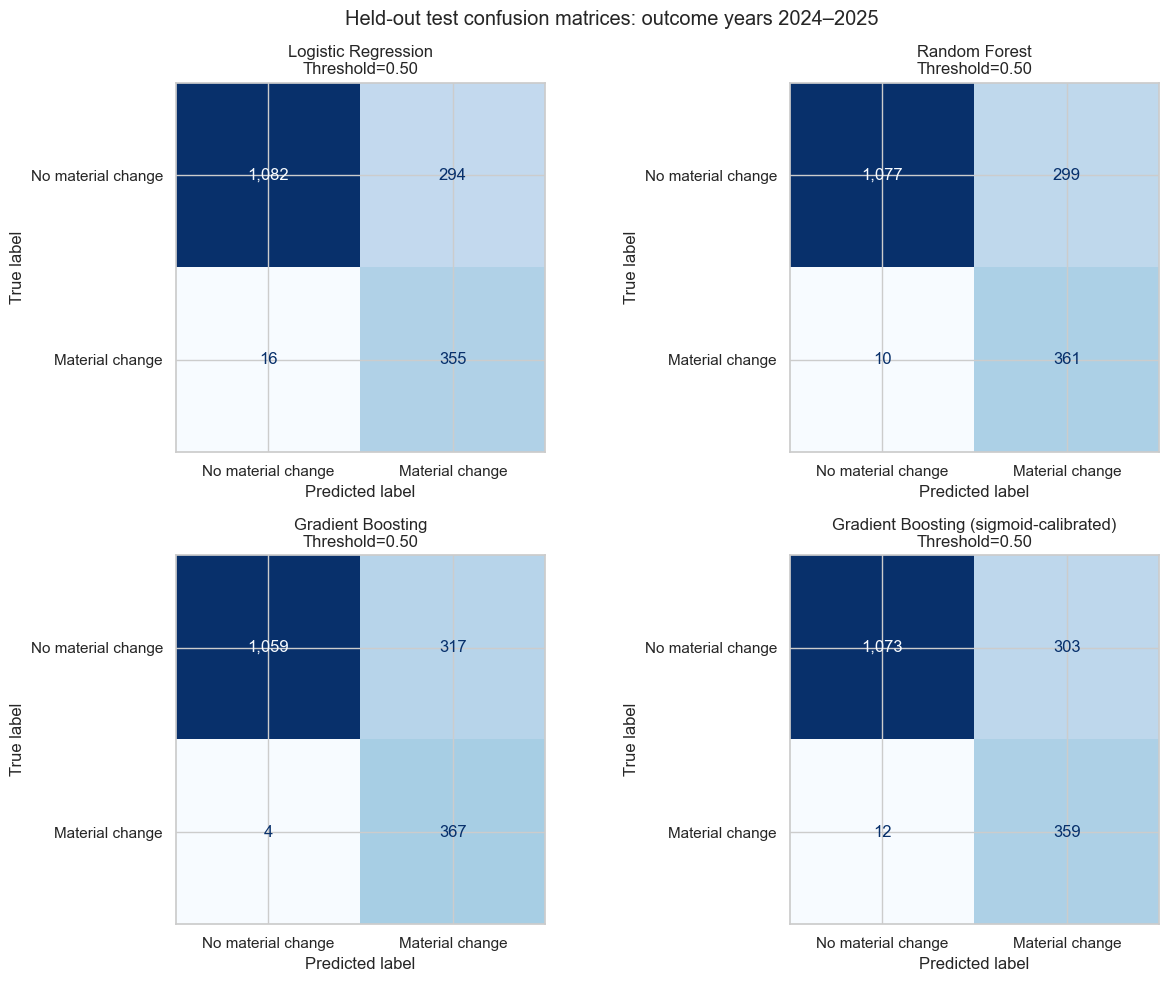

In [61]:
confusion_rows = []
for model_name, prediction in test_predictions.items():
    tn, fp, fn, tp = confusion_matrix(y_test, prediction, labels=[0, 1]).ravel()
    confusion_rows.append({
        "Model": model_name,
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "Sensitivity_Recall": tp / (tp + fn) if tp + fn else np.nan,
        "Specificity": tn / (tn + fp) if tn + fp else np.nan,
        "False_Positive_Rate": fp / (fp + tn) if fp + tn else np.nan,
        "False_Negative_Rate": fn / (fn + tp) if fn + tp else np.nan,
    })
confusion_summary = pd.DataFrame(confusion_rows)
display(confusion_summary.round(4))

plot_names = list(candidate_models.keys()) + [calibrated_result_name]
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, model_name in zip(axes.ravel(), plot_names):
    cm = confusion_matrix(y_test, test_predictions[model_name], labels=[0, 1])
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No material change", "Material change"],
    ).plot(ax=ax, cmap="Blues", colorbar=False, values_format=",")
    ax.set_title(f"{model_name}\nThreshold=0.50")
plt.suptitle("Held-out test confusion matrices: outcome years 2024–2025")
plt.tight_layout()
plt.show()

### 13.2 ROC and precision–recall curves

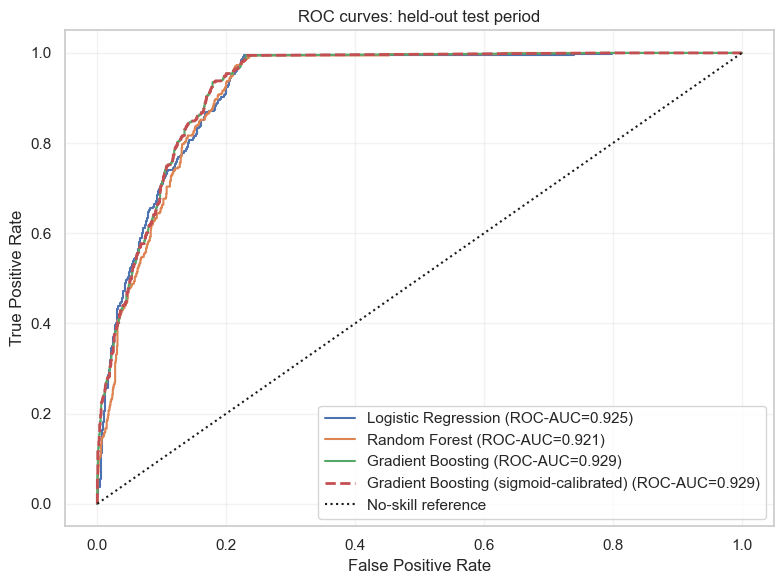

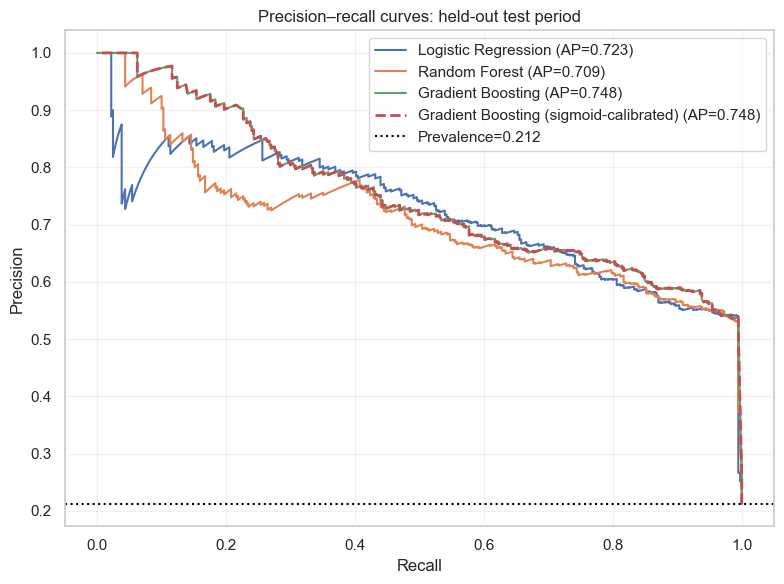

In [62]:
plt.figure(figsize=(8, 6))
for model_name in candidate_models:
    fpr, tpr, _ = roc_curve(y_test, test_probabilities[model_name])
    auc_value = roc_auc_score(y_test, test_probabilities[model_name])
    plt.plot(fpr, tpr, label=f"{model_name} (ROC-AUC={auc_value:.3f})")

cal_fpr, cal_tpr, _ = roc_curve(y_test, calibrated_test_prob)
cal_auc = roc_auc_score(y_test, calibrated_test_prob)
plt.plot(cal_fpr, cal_tpr, linestyle="--", linewidth=2,
         label=f"{calibrated_result_name} (ROC-AUC={cal_auc:.3f})")
plt.plot([0, 1], [0, 1], "k:", label="No-skill reference")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curves: held-out test period")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
for model_name in candidate_models:
    precision, recall, _ = precision_recall_curve(y_test, test_probabilities[model_name])
    ap = average_precision_score(y_test, test_probabilities[model_name])
    plt.plot(recall, precision, label=f"{model_name} (AP={ap:.3f})")
cal_precision, cal_recall, _ = precision_recall_curve(y_test, calibrated_test_prob)
cal_ap = average_precision_score(y_test, calibrated_test_prob)
plt.plot(cal_recall, cal_precision, linestyle="--", linewidth=2,
         label=f"{calibrated_result_name} (AP={cal_ap:.3f})")
plt.axhline(y=y_test.mean(), color="black", linestyle=":", label=f"Prevalence={y_test.mean():.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–recall curves: held-out test period")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 14. Probability calibration assessment

The sigmoid calibrator was fitted on the 2023 calibration period. Its performance is assessed independently on the 2024–2025 test period using Brier score, log loss and a reliability diagram. The test period is not used to refit the calibrator. A lower Brier score or log loss indicates better probabilistic accuracy.

,Probability_Model,Brier_Score,Log_Loss
0,Selected model before calibration,0.1153,0.3385
1,Selected model after sigmoid calibration,0.1031,0.2959


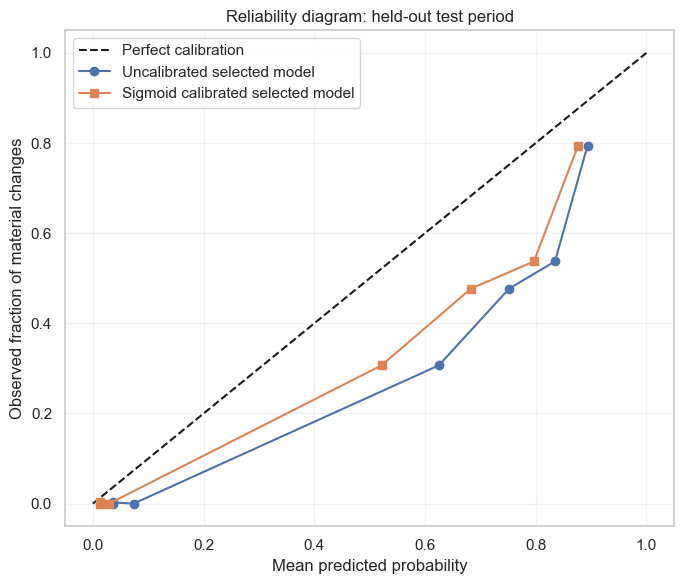

Calibration fitted on outcome year: 2023
Calibration quality assessed on outcome years: [2024, 2025]


In [63]:
raw_selected_test_prob = test_probabilities[selected_model_name]
calibration_test_results = pd.DataFrame([
    {
        "Probability_Model": "Selected model before calibration",
        "Brier_Score": brier_score_loss(y_test, raw_selected_test_prob),
        "Log_Loss": log_loss(y_test, raw_selected_test_prob, labels=[0, 1]),
    },
    {
        "Probability_Model": "Selected model after sigmoid calibration",
        "Brier_Score": brier_score_loss(y_test, calibrated_test_prob),
        "Log_Loss": log_loss(y_test, calibrated_test_prob, labels=[0, 1]),
    },
])
display(calibration_test_results.round(4))

raw_fraction, raw_mean = calibration_curve(
    y_test, raw_selected_test_prob, n_bins=10, strategy="quantile"
)
cal_fraction, cal_mean = calibration_curve(
    y_test, calibrated_test_prob, n_bins=10, strategy="quantile"
)
plt.figure(figsize=(7, 6))
plt.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
plt.plot(raw_mean, raw_fraction, marker="o", label="Uncalibrated selected model")
plt.plot(cal_mean, cal_fraction, marker="s", label="Sigmoid calibrated selected model")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed fraction of material changes")
plt.title("Reliability diagram: held-out test period")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print("Calibration fitted on outcome year:", CALIBRATION_OUTCOME_YEAR)
print("Calibration quality assessed on outcome years:", TEST_OUTCOME_YEARS)

## 15. Sensitivity analysis: alternative material-change definitions

The primary target is a five-percentage-point change in **at least one individual asset-class share**. Sensitivity analysis repeats the Logistic Regression workflow at alternative cutoffs of 3%, 4%, 10%, 15% and 20%, alongside the primary 5% definition. For each cutoff, labels are reconstructed from the same maximum-single-asset-class-change measure. The model is fitted on outcomes through 2022, calibrated on 2023, and evaluated on 2024–2025. The same pre-specified calibrated probability threshold of 0.50 is used for every cutoff; no threshold is tuned using the calibration or test outcomes.

In [64]:
SENSITIVITY_THRESHOLDS = [0.03, 0.04, 0.05, 0.10, 0.15, 0.20]
MAXIMUM_CHANGE_COLUMN = "Maximum_Future_Asset_Class_Change"
sensitivity_rows = []
sensitivity_models = {}

for cutoff in SENSITIVITY_THRESHOLDS:
    y_train_alt = (train_classification[MAXIMUM_CHANGE_COLUMN] >= cutoff).astype(int)
    y_calibration_alt = (calibration_classification[MAXIMUM_CHANGE_COLUMN] >= cutoff).astype(int)
    y_test_alt = (test_classification[MAXIMUM_CHANGE_COLUMN] >= cutoff).astype(int)

    if any(y.nunique() < 2 for y in [y_train_alt, y_calibration_alt, y_test_alt]):
        sensitivity_rows.append({
            "Materiality_Cutoff": cutoff,
            "Status": "Not evaluated: a partition contains only one class",
        })
        continue

    sensitivity_base_model = clone(candidate_models["Logistic Regression"])
    sensitivity_base_model.fit(
        X_train,
        y_train_alt,
    )

    try:
        sensitivity_frozen = FrozenEstimator(sensitivity_base_model)
        sensitivity_calibrator = CalibratedClassifierCV(
            estimator=sensitivity_frozen, method="sigmoid"
        )
    except NameError:
        sensitivity_calibrator = CalibratedClassifierCV(
            estimator=sensitivity_base_model, method="sigmoid", cv="prefit"
        )

    sensitivity_calibrator.fit(X_calibration, y_calibration_alt)
    test_prob = sensitivity_calibrator.predict_proba(X_test)[:, 1]
    metrics = evaluate_binary_classifier(
        y_test_alt, test_prob, threshold=CALIBRATED_DECISION_THRESHOLD
    )
    tn, fp, fn, tp = confusion_matrix(
        y_test_alt, (test_prob >= CALIBRATED_DECISION_THRESHOLD).astype(int), labels=[0, 1]
    ).ravel()

    sensitivity_models[cutoff] = sensitivity_calibrator
    sensitivity_rows.append({
        "Materiality_Cutoff": cutoff,
        "Status": "Evaluated",
        "Training_Positive_Rate": float(y_train_alt.mean()),
        "Calibration_Positive_Rate": float(y_calibration_alt.mean()),
        "Test_Positive_Rate": float(y_test_alt.mean()),
        "Decision_Threshold": CALIBRATED_DECISION_THRESHOLD,
        "Test_Balanced_Accuracy": metrics["Balanced_Accuracy"],
        "Test_Precision": metrics["Precision"],
        "Test_Recall": metrics["Recall"],
        "Test_F1": metrics["F1"],
        "Test_ROC_AUC": metrics["ROC_AUC"],
        "Test_PR_AUC_Average_Precision": metrics["PR_AUC_Average_Precision"],
        "Test_Brier_Score": metrics["Brier_Score"],
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    })

sensitivity_analysis_results = pd.DataFrame(sensitivity_rows)
display(sensitivity_analysis_results.round(4))

,Materiality_Cutoff,Status,Training_Positive_Rate,Calibration_Positive_Rate,Test_Positive_Rate,Decision_Threshold,Test_Balanced_Accuracy,Test_Precision,Test_Recall,Test_F1,Test_ROC_AUC,Test_PR_AUC_Average_Precision,Test_Brier_Score,TN,FP,FN,TP
0,0.0300,Evaluated,0.2718,0.3079,0.3045,0.5000,0.9352,0.7831,0.9906,0.8747,0.9556,0.8618,0.0706,1069,146,5,527
1,0.0400,Evaluated,0.2396,0.2766,0.2599,0.5000,0.9009,0.6657,0.9736,0.7907,0.9390,0.7942,0.0907,1071,222,12,442
2,0.0500,Evaluated,0.2064,0.2478,0.2124,0.5000,0.8675,0.5522,0.9407,0.6959,0.9247,0.7230,0.1008,1093,283,22,349
3,0.1000,Evaluated,0.1011,0.1089,0.1002,0.5000,0.6067,0.6250,0.2286,0.3347,0.9017,0.5018,0.0664,1548,24,135,40
4,0.1500,Evaluated,0.0655,0.0538,0.0567,0.5000,0.5543,0.7333,0.1111,0.1930,0.8643,0.3467,0.0444,1644,4,88,11
5,0.2000,Evaluated,0.0491,0.0375,0.0401,0.5000,0.5571,1.0000,0.1143,0.2051,0.8440,0.3131,0.0324,1677,0,62,8


## 16. Model interpretation using SHAP

SHAP (SHapley Additive exPlanations) describes how predictors contribute to the selected **base estimator's** output. The explanation sample is drawn reproducibly from the held-out test predictors, while the background sample comes from the final training predictors. For this reason, the SHAP analysis explains the selected model before the separate sigmoid calibration layer. SHAP values describe model behaviour and associations; they do **not** establish causal effects.

In [65]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [66]:
# Install in the active notebook kernel if SHAP is unavailable: %pip install shap
import shap

selected_preprocessor = selected_base_model.named_steps["preprocessor"]
selected_classifier = selected_base_model.named_steps["classifier"]
background_raw = X_train.sample(n=min(100, len(X_train)), random_state=RANDOM_STATE)
explain_raw = X_test.sample(n=min(250, len(X_test)), random_state=RANDOM_STATE)
background_transformed = selected_preprocessor.transform(background_raw)
explain_transformed = selected_preprocessor.transform(explain_raw)
transformed_feature_names = selected_preprocessor.get_feature_names_out()

if hasattr(selected_classifier, "coef_"):
    shap_explainer = shap.LinearExplainer(selected_classifier, background_transformed)
else:
    shap_explainer = shap.TreeExplainer(selected_classifier)
shap_values_raw = shap_explainer.shap_values(explain_transformed)

# Support SHAP output formats used by binary classifiers across versions.
if isinstance(shap_values_raw, list):
    shap_values = np.asarray(shap_values_raw[1])
else:
    shap_values = np.asarray(shap_values_raw)
    if shap_values.ndim == 3 and shap_values.shape[-1] == 2:
        shap_values = shap_values[:, :, 1]
    elif shap_values.ndim == 3 and shap_values.shape[0] == 2:
        shap_values = shap_values[1]

if shap_values.ndim != 2 or shap_values.shape[1] != len(transformed_feature_names):
    raise ValueError(
        f"Unexpected SHAP output shape {shap_values.shape}; expected a 2D matrix "
        f"with {len(transformed_feature_names)} columns."
    )

shap_input = pd.DataFrame(
    np.asarray(explain_transformed),
    columns=transformed_feature_names,
    index=explain_raw.index,
)
shap_importance = pd.DataFrame({
    "Feature": transformed_feature_names,
    "Mean_Absolute_SHAP": np.abs(shap_values).mean(axis=0),
}).sort_values("Mean_Absolute_SHAP", ascending=False).reset_index(drop=True)
print("Base model explained:", selected_model_name)
print("Held-out test observations explained:", len(explain_raw))
display(shap_importance.head(20).round(6))

c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Base model explained: Gradient Boosting
Held-out test observations explained: 250


,Feature,Mean_Absolute_SHAP
0,numeric__Guaranteed_Funds_Share,2.1863
1,numeric__Cash_Share,0.2368
2,numeric__Portfolio_HHI,0.1412
3,numeric__Year,0.0600
4,numeric__Log_Total_Investments,0.0600
5,numeric__Change_Cash_Share,0.0494
6,numeric__Government_Securities_Share,0.0489
7,numeric__Change_Government_Securities_Share,0.0488
8,numeric__HHI_Change,0.0385
9,numeric__Change_Corporate_Bonds_Share,0.0349


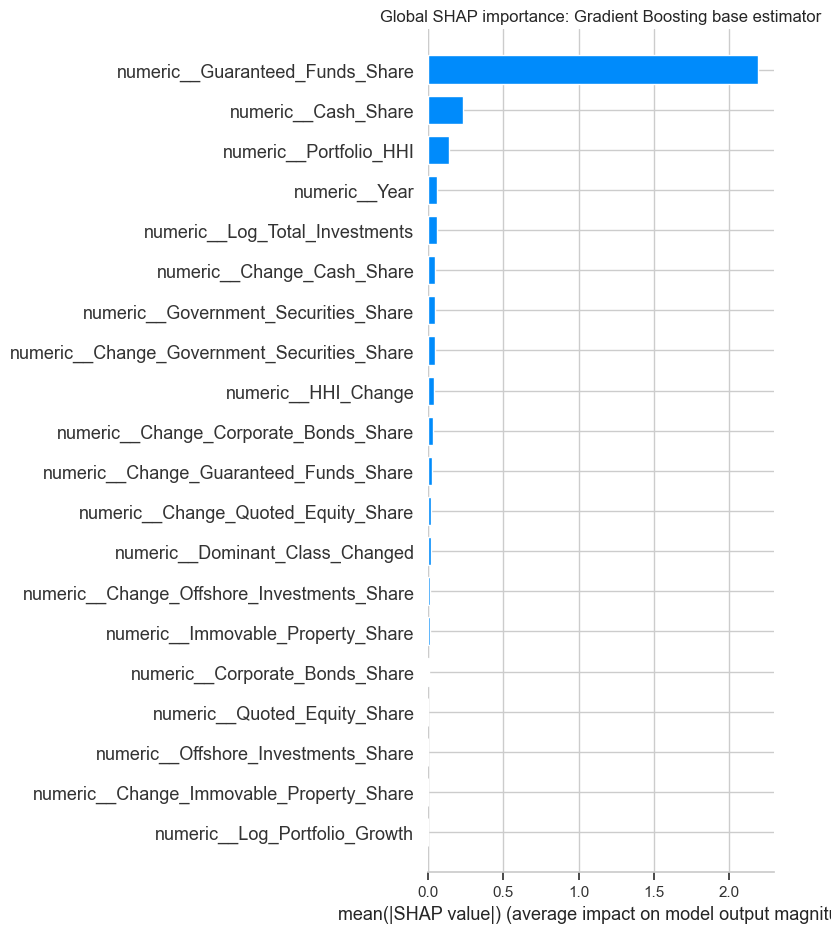

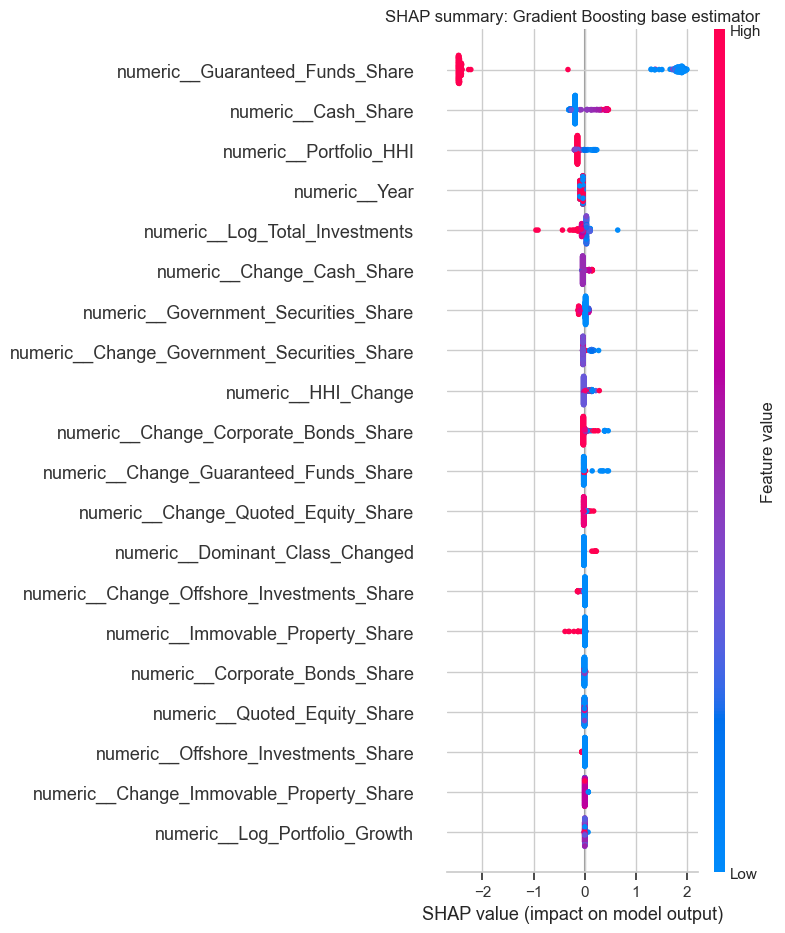

In [67]:
shap.summary_plot(shap_values, shap_input, plot_type="bar", max_display=20, show=False)
plt.title(f"Global SHAP importance: {selected_model_name} base estimator")
plt.tight_layout()
plt.show()

shap.summary_plot(shap_values, shap_input, max_display=20, show=False)
plt.title(f"SHAP summary: {selected_model_name} base estimator")
plt.tight_layout()
plt.show()

## 17. Save the selected calibrated model and metadata

The selected classifier is chosen using mean Average Precision across the 2020–2022 expanding-window folds. It is refitted on all pre-calibration observations (outcome years through 2022), then sigmoid-calibrated on the separate 2023 outcome year. The final 2024–2025 test set is not used for fitting, calibration, model selection or threshold selection. The saved artifact contains the fitted preprocessing, classifier and calibrator for the later API stage.

In [68]:
import json
import joblib

# Save artifacts beside the source dataset's project root.
data_parent = Path(DATA_PATH).resolve().parent
if data_parent.name.lower() == "raw" and data_parent.parent.name.lower() == "data":
    PROJECT_ROOT = data_parent.parent.parent
elif data_parent.name.lower() == "data":
    PROJECT_ROOT = data_parent.parent
else:
    PROJECT_ROOT = data_parent

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
MODEL_ARTIFACT_PATH = MODEL_DIR / "material_allocation_change_model.joblib"
MODEL_METADATA_PATH = MODEL_DIR / "model_metadata.json"
CV_RESULTS_PATH = MODEL_DIR / "temporal_validation_results.csv"

joblib.dump(calibrated_selected_model, MODEL_ARTIFACT_PATH)
model_metadata = {
    "project": "Predicting Material Asset-Allocation Changes among Retirement Benefits Schemes in Kenya",
    "selected_model": selected_model_name,
    "model_selection_metric": "Mean PR-AUC (Average Precision) across expanding-window temporal validation folds",
    "temporal_validation_outcome_years": TEMPORAL_CV_YEARS,
    "temporal_validation_fold_definitions": [
        {"training_outcome_years": "through 2019", "validation_outcome_year": 2020},
        {"training_outcome_years": "through 2020", "validation_outcome_year": 2021},
        {"training_outcome_years": "through 2021", "validation_outcome_year": 2022},
    ],
    "target_name": classification_target,
    "positive_class": "At least one asset-class share changes by 5 percentage points or more in the next consecutive reporting year",
    "material_change_threshold": MATERIAL_CHANGE_THRESHOLD,
    "final_model_training_outcome_years": [int(train_classification.Next_Year.min()), int(train_classification.Next_Year.max())],
    "probability_calibration": "Sigmoid calibration fitted on outcome year 2023 with the base estimator frozen",
    "calibration_outcome_year": CALIBRATION_OUTCOME_YEAR,
    "api_decision_threshold_for_calibrated_probability": CALIBRATED_DECISION_THRESHOLD,
    "threshold_selection": "Pre-specified 0.50 threshold after calibration; no threshold optimisation on the calibration year",
    "held_out_test_outcome_years": TEST_OUTCOME_YEARS,
    "predictor_features": classification_features,
    "final_training_observations": int(len(train_classification)),
    "calibration_observations": int(len(calibration_classification)),
    "test_observations": int(len(test_classification)),
    "test_set_used_for_fitting_or_selection": False,
    "interpretation_note": "This is a decision-support monitoring signal, not a determination that a portfolio change is harmful or non-compliant.",
}
with open(MODEL_METADATA_PATH, "w", encoding="utf-8") as f:
    json.dump(model_metadata, f, indent=2)
temporal_cv_results.to_csv(CV_RESULTS_PATH, index=False)

print("Calibrated model saved:", MODEL_ARTIFACT_PATH.resolve())
print("Model metadata saved:", MODEL_METADATA_PATH.resolve())
print("Fold-level validation results saved:", CV_RESULTS_PATH.resolve())
print("Model size (MB):", round(MODEL_ARTIFACT_PATH.stat().st_size / (1024 ** 2), 2))

Calibrated model saved: C:\Users\User\OneDrive\Documents\AML CAPSTONE PROJECT\models\material_allocation_change_model.joblib
Model metadata saved: C:\Users\User\OneDrive\Documents\AML CAPSTONE PROJECT\models\model_metadata.json
Fold-level validation results saved: C:\Users\User\OneDrive\Documents\AML CAPSTONE PROJECT\models\temporal_validation_results.csv
Model size (MB): 0.12


### 17.1 Reload and smoke-test the serialized model

In [69]:
reloaded_model = joblib.load(MODEL_ARTIFACT_PATH)
reloaded_probabilities = reloaded_model.predict_proba(X_test.iloc[:5])[:, 1]
assert reloaded_probabilities.shape == (min(5, len(X_test)),)
assert np.isfinite(reloaded_probabilities).all()
assert ((reloaded_probabilities >= 0) & (reloaded_probabilities <= 1)).all()
print("Serialized calibrated model reload and prediction smoke test: PASSED")
display(pd.DataFrame({
    "Predicted_Probability": reloaded_probabilities,
    "Predicted_Class_at_0.50": (reloaded_probabilities >= CALIBRATED_DECISION_THRESHOLD).astype(int),
}).round(4))

Serialized calibrated model reload and prediction smoke test: PASSED


,Predicted_Probability,Predicted_Class_at_0.50
0,0.7082,1
1,0.5537,1
2,0.9200,1
3,0.9002,1
4,0.8788,1


## 18. Machine-learning stage: final checkpoint

This notebook covers data preparation, feature engineering, descriptive portfolio and transition analysis, construction of the five-percentage-point binary target, expanding-window temporal validation (2020–2022), model comparison, refitting on outcomes through 2022, sigmoid probability calibration on 2023, final out-of-time testing on 2024–2025, sensitivity analysis, SHAP interpretation and model serialization.

### Interpretation and methodological cautions

- A material change is an observed allocation movement, not evidence of poor performance, inappropriate risk-taking or non-compliance.
- Expanding-window folds preserve temporal order: each validation year is later than the observations used to fit that fold.
- The 2023 period is reserved for probability calibration, and the classification threshold is fixed at 0.50 rather than optimised on the calibration sample.
- The 2024–2025 test period is not used for model selection, calibration, threshold setting or model fitting.
- Schemes may overlap between chronological periods. Results concern forecasting future-year outcomes for schemes with historical records; they do not establish performance on entirely unseen schemes.
- SHAP explains the selected base estimator and its associations; it does not establish causation or explain the additional calibration transformation.
- Model configurations are pre-specified candidates, not the results of an exhaustive hyperparameter search.

**Next stage:** extract the validated workflow into reproducible Python scripts, then develop the prediction API, Docker configuration and repository documentation. The notebook documents the analysis but does not replace the required scripted pipeline.

In [70]:
from pathlib import Path

print("Notebook working directory:")
print(Path.cwd())

print("\nDoes the CSV exist at our known location?")

csv_path = Path(
    r"C:\Users\User\OneDrive\Documents\AML CAPSTONE PROJECT\COPY 1 FINAL.csv"
)

print(csv_path.is_file())

Notebook working directory:
c:\Users\User\OneDrive\Documents\AML CAPSTONE PROJECT

Does the CSV exist at our known location?
True


In [71]:
import sys

print(sys.executable)
print(sys.version)

c:\Users\User\AppData\Local\Programs\Python\Python313\python.exe
3.13.5 (tags/v3.13.5:6cb20a2, Jun 11 2025, 16:15:46) [MSC v.1943 64 bit (AMD64)]


In [72]:
import sys

print("Python executable:", sys.executable)
print("Python version:", sys.version)

Python executable: c:\Users\User\AppData\Local\Programs\Python\Python313\python.exe
Python version: 3.13.5 (tags/v3.13.5:6cb20a2, Jun 11 2025, 16:15:46) [MSC v.1943 64 bit (AMD64)]


In [73]:
# Create a sample input for testing the prediction script

prediction_input = X_train.iloc[[0]].copy()

# Save only the 26 predictor variables
prediction_input.to_csv(
    "prediction_input_smoke_test.csv",
    index=False
)

print("Prediction input created successfully!")
print("Input shape:", prediction_input.shape)
display(prediction_input)

Prediction input created successfully!
Input shape: (1, 26)


,Cash_Share,Corporate_Bonds_Share,Guaranteed_Funds_Share,Immovable_Property_Share,Government_Securities_Share,Offshore_Investments_Share,Property_Unit_Trusts_Share,Quoted_Equity_Share,Unquoted_Equity_Share,Change_Cash_Share,Change_Corporate_Bonds_Share,Change_Guaranteed_Funds_Share,Change_Immovable_Property_Share,Change_Government_Securities_Share,Change_Offshore_Investments_Share,Change_Property_Unit_Trusts_Share,Change_Quoted_Equity_Share,Change_Unquoted_Equity_Share,Portfolio_HHI,Active_Asset_Classes,HHI_Change,Dominant_Class_Changed,Log_Total_Investments,Log_Portfolio_Growth,Year,Dominant_Asset_Class
1,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,1,0.0000,0,16.8738,0.2335,2016,Guaranteed Funds
